# Decoding the Subsurface: lithology segmentation and clustering

**Viridien challenge, HackTheBurgh 2026.** One notebook that explains the challenge, the dataset, what makes it hard,
how we score answers, eleven strategies with code and real demo images, their trade-offs, the research behind the
next upgrades, and the live bake-off results.

All images are embedded at full resolution, so the notebook reads without running anything. Run it from
`viridien_work/` to refresh the results section.

In [1]:
import json, glob, os, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_colwidth", 80)
os.getcwd()

'C:\\Users\\hssil\\Downloads\\03_Programming_Projects\\hacktheburgh\\viridien_work'

## 1. The task

For every scanned mud log, output one CSV of **contiguous intervals** down the interpreted lithology column:

`top_depth, bottom_depth, lithology, top_y, bottom_y, cluster_id`

plus an annotated image. `lithology` is a name from the log's own legend, and `cluster_id` groups intervals with the same
visual pattern. Judged on **correctness** and **efficiency**. Bonus: find the depth column, the lithology column and the
legend without the supplied boxes.

Every log goes through four steps:

| Step | What it does |
|---|---|
| 1. Split | find each interval's top and bottom pixel row |
| 2. Group | same pattern, same `cluster_id` |
| 3. Name | match each group to a legend swatch |
| 4. Depth | read the depth column and fit pixel row to feet |

The only true answer supplied is for log06 (17 intervals):

In [2]:
gold = pd.read_csv("bakeoff/gt/gold/0000000009_d-582_0000020435-0001_log06_fe_5in_md.csv")
gold.head(10)

,top_depth,bottom_depth,lithology,top_y,bottom_y,cluster_id
0,25400,25420,Shale,4409,4809,0
1,25420,25430,Siltstone,4809,5010,1
2,25430,25490,Shale,5010,6211,0
3,25490,25500,Siltstone,6211,6411,1
4,25500,25510,Shale,6411,6611,0
5,25510,25520,Sandstone,6611,6811,2
6,25520,25530,Siltstone,6811,7012,1
7,25530,25540,Sandstone,7012,7212,2
8,25540,25550,Siltstone,7212,7412,1
9,25550,25560,Shale,7412,7612,0


What it looks like drawn with the organisers' `visualize_results` (full page at 0.1 scale, then a zoom at 0.5):

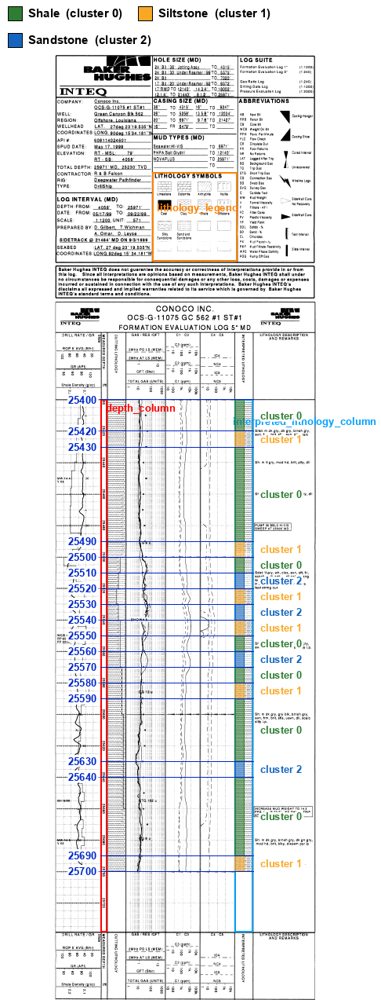

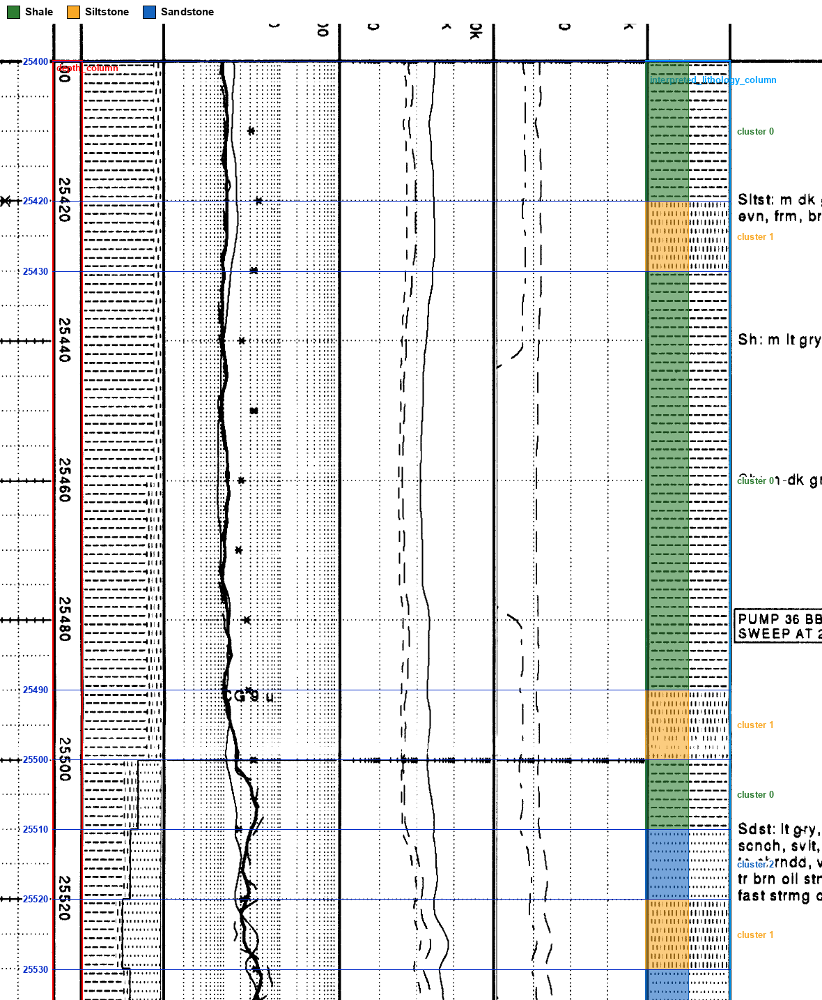

In [3]:
display(Image(filename=r"artifact/img/f01_notebook_full.png"))
display(Image(filename=r"artifact/img/f02_notebook_zoom.png"))

## 2. The dataset, and how varied it is

51 annotated TIFF logs, 7.3 gigapixels in total. Every size varies by 10x to 100x:

In [4]:
d = pd.read_csv("figs/dataset_stats.csv")
d["aspect"] = (d.height / d.width).round(1)
d["col_pct_of_page"] = (100 * d.col_w / d.width).round(1)
print("image modes:", d["mode"].value_counts().to_dict(), "(1 = 1-bit black and white, P = palette)")
d[["width", "height", "col_w", "col_h", "legend_w", "legend_h", "aspect", "col_pct_of_page"]].describe().loc[["min", "50%", "max"]].round(1)

image modes: {'RGB': 36, '1': 9, 'P': 6} (1 = 1-bit black and white, P = palette)


,width,height,col_w,col_h,legend_w,legend_h,aspect,col_pct_of_page
min,1275.0,2600.0,29.0,999.0,583.0,164.0,1.7,2.0
50%,1700.0,44550.0,63.0,38251.0,1530.0,407.0,28.5,4.0
max,4864.0,313800.0,297.0,307092.0,2310.0,1142.0,186.8,6.1


| Quantity | Range |
|---|---|
| page height | 2,600 to 313,800 px (median 44,550): 120x |
| lithology column width | 29 to 297 px, only 2 to 6 % of the page |
| depth scale | 0.05 to 0.5 ft per px across the 13 test logs: 10x |
| rock entries per legend | 2 to 30, plus up to 20 non-rock symbols |
| image modes | 36 RGB, 9 1-bit, 6 palette |

**About eight legend families, not 51 random logs** (counts marked ~ come from file names and the legend sheet):

| Family | Logs | Rock column | What breaks |
|---|---|---|---|
| D-582 well, "LITHOLOGY SYMBOLS" grid | 9 | 1-bit hatches only | colour methods see nothing; Shale, Clay and Silty Sandstone are all dash patterns |
| Gulf of Mexico 3-panel (Lithology / Modifiers / Show & drilling) | ~20 | flat colour, often one colour for thousands of rows | parser must drop the modifier and drilling panels; tiny text |
| Geoservices "Lithology Legend" grid | ~4 | colour plus pattern | several sandstones share yellow and differ only in dot density |
| Mineral / Lithology split (MC761) | 3 | colour fills | a mineral list sits beside the rock list |
| MC765 colour-only grid | 4 | colour fills | same well at 1 inch and 5 inch, MD and TVD |
| Texas onshore "Rock Types" box | ~7 | coloured stripes with symbols | labels a few pixels high |
| One-offs (Allegheny, Trail Mountain, Freeman, Shell) | ~4 | bold colour plus hatch | layouts seen once |

**The same word means different pictures.** Sandstone is a dotted white box in D-582, plain yellow in the Gulf logs,
yellow with dots in Geoservices and a striped band in Texas. So every log must be matched against *its own* legend.

**Near-duplicates.** D-582 appears 9 times, MC765 4 times, MC761 3 times. Anything tuned on log06 will look better on
log02 and log04 than it really is, so results are reported for D-582 and the rest separately.

### All 51 legends

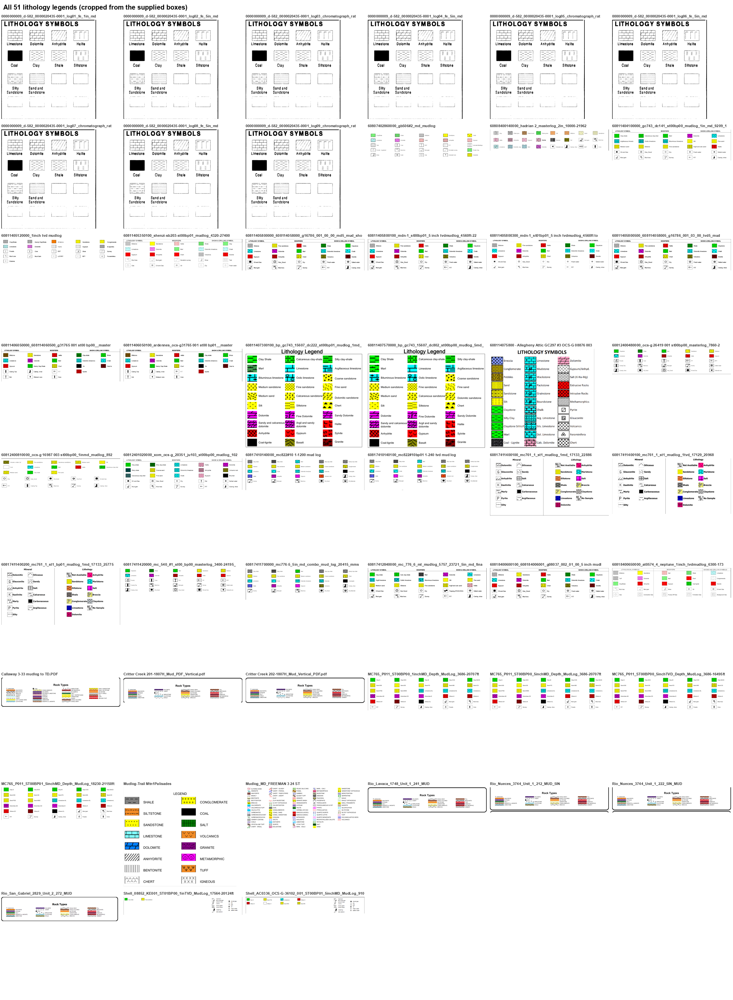

In [5]:
display(Image(filename=r"figs/01_all_legends.png"))

### The depth and lithology columns, 3,000 px from 40 % down each log

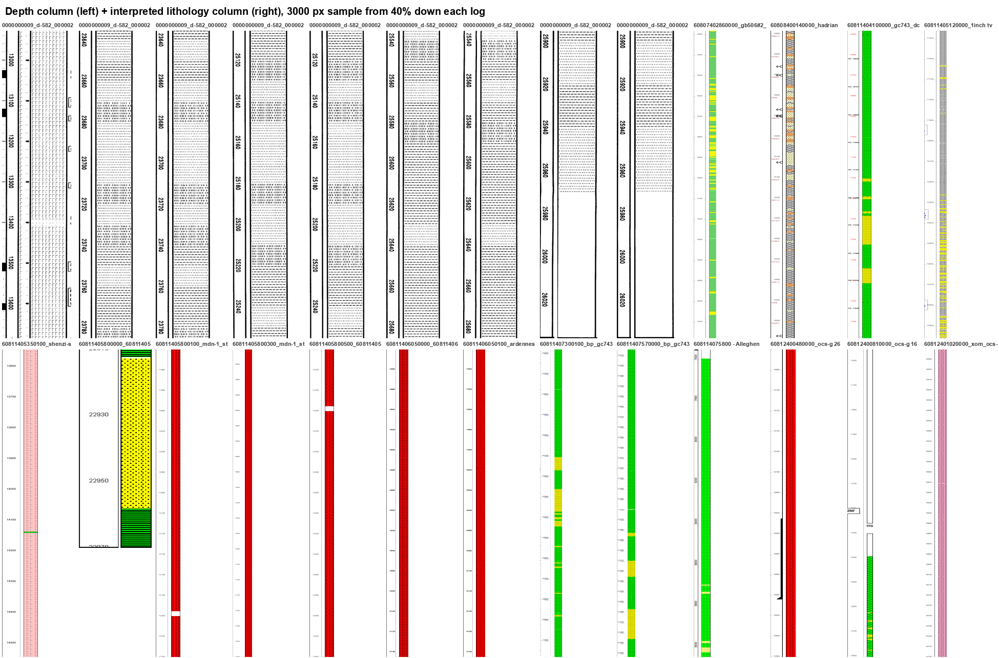

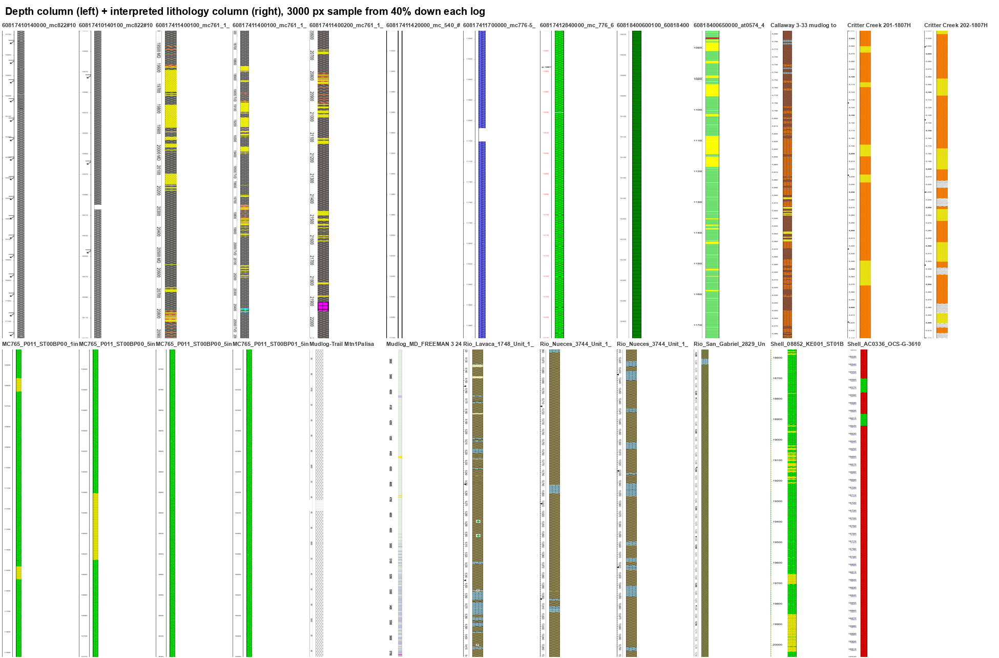

In [6]:
display(Image(filename=r"figs/02_columns_1.png"))
display(Image(filename=r"figs/02_columns_2.png"))

### Whole pages (contact sheets)

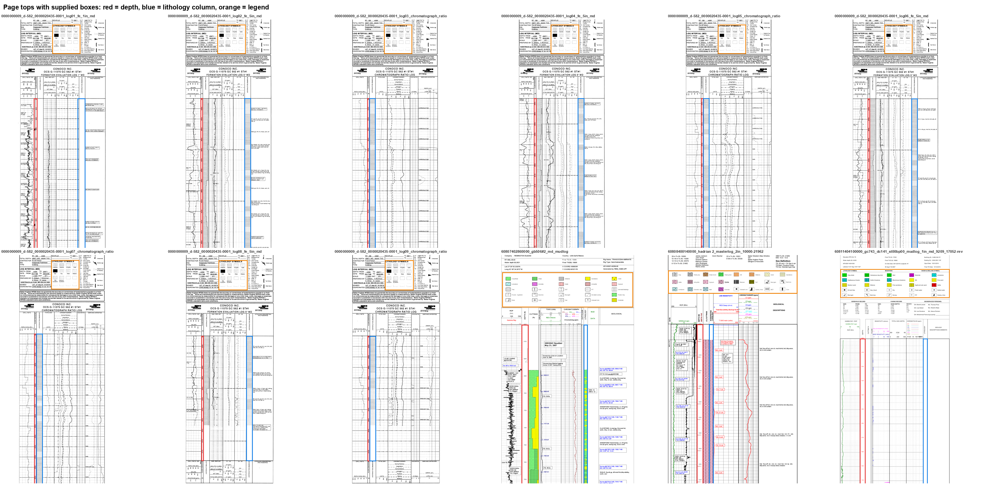

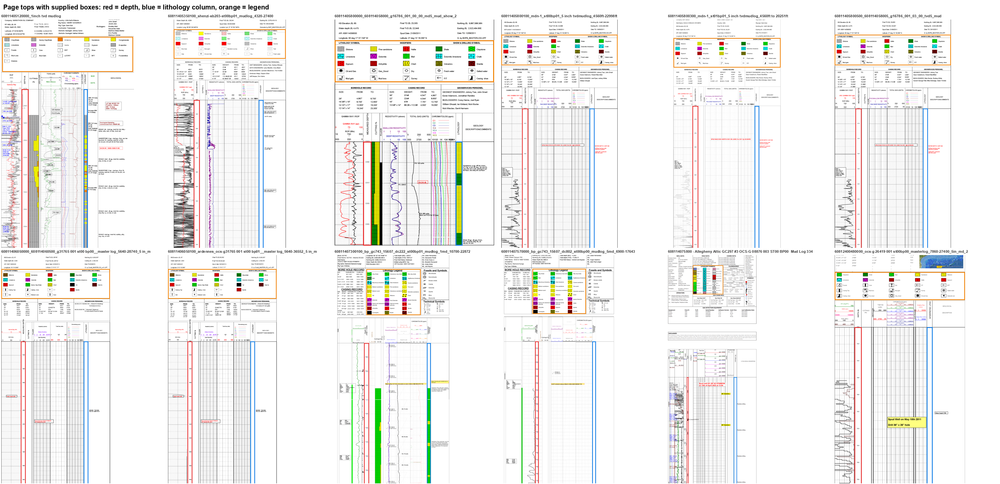

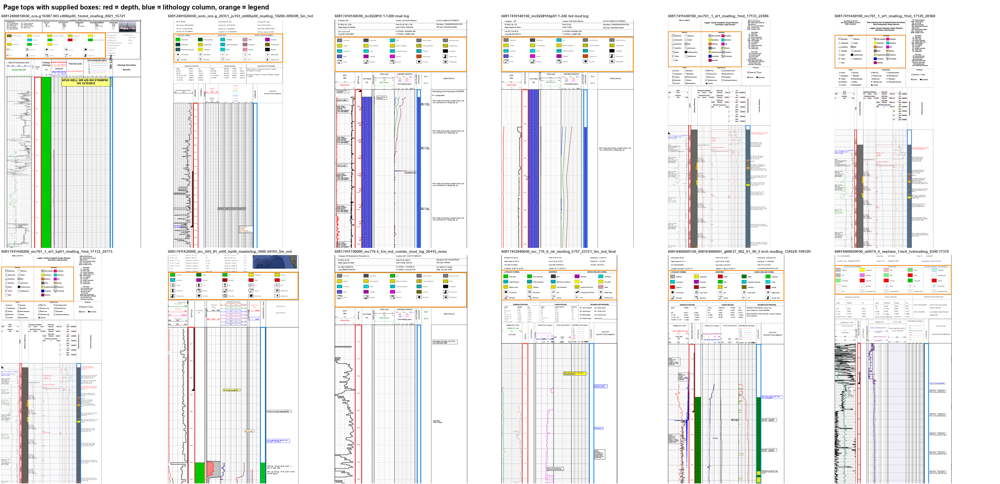

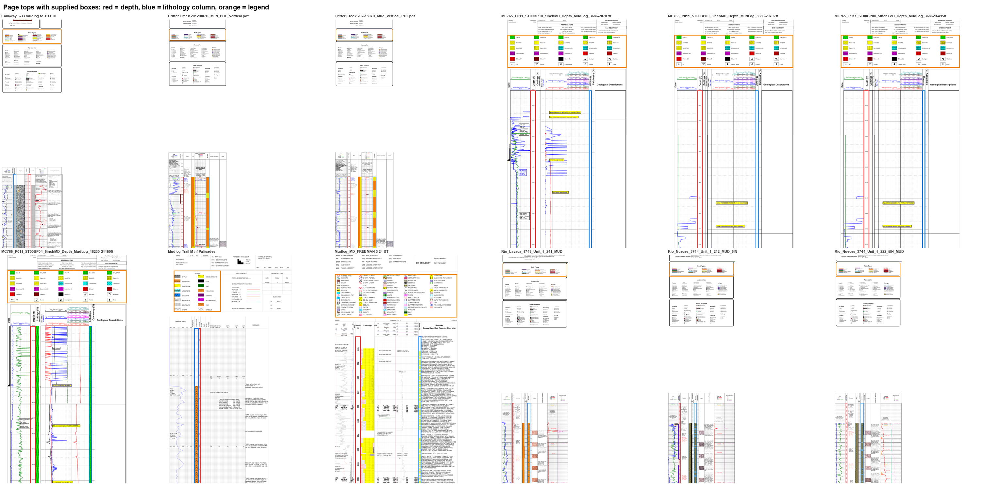

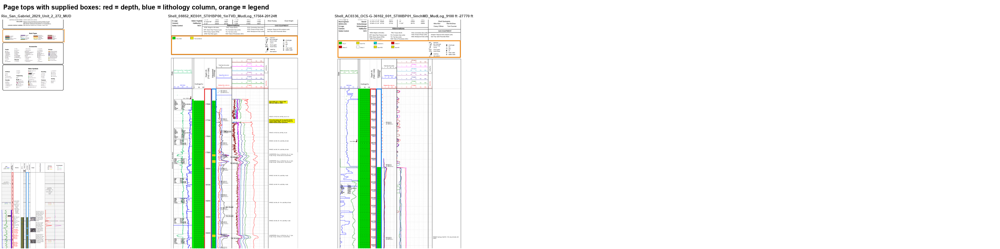

In [7]:
display(Image(filename=r"figs/03_pages_1.png"))
display(Image(filename=r"figs/03_pages_2.png"))
display(Image(filename=r"figs/03_pages_3.png"))
display(Image(filename=r"figs/03_pages_4.png"))
display(Image(filename=r"figs/03_pages_5.png"))

## 3. The inputs: three boxes per page

Each annotation gives `[x0, y0, x1, y1]` (max exclusive) for **1 depth_column (red)**,
**2 interpreted_lithology_column (blue)** and **3 lithology_legend (orange)**, drawn here like the notebook's `draw_boxes`.

In [8]:
m = json.load(open("artifact/manifest.json", encoding="utf8"))
pd.DataFrame([{"figure": k, "page": v["page"], **v["boxes"]} for k, v in m.items() if k.startswith("f03")])

,figure,page,depth_column,interpreted_lithology_column,lithology_legend
0,f03_boxes_1.png,0000000009_d-582_0000020435-0001_log06_fe_5in_md,"[1288, 4404, 1376, 11195]","[2991, 4404, 3237, 11195]","[1943, 1513, 3035, 2655]"
1,f03_boxes_2.png,60811407300100_bp_gc743_15607_dc222_st00bp01_mudlog_1md_10700-22872,"[415, 1543, 485, 25948]","[1300, 1543, 1355, 25948]","[447, 498, 1213, 1147]"
2,f03_boxes_3.png,60807402860000_gb506#2_md_mudlog,"[236, 1206, 316, 9623]","[953, 1206, 1000, 9623]","[12, 596, 1525, 1003]"
3,f03_boxes_4.png,Critter Creek 201-1807H_Mud_PDF_Vertical.pdf,"[277, 5480, 338, 43731]","[817, 5480, 893, 43731]","[28, 2276, 1248, 2529]"
4,f03_boxes_5.png,Rio_Nueces_3744_Unit_1_212_MUD_5IN,"[280, 6861, 321, 120865]","[661, 6861, 731, 120865]","[34, 3299, 1667, 3644]"
5,f03_boxes_6.png,608114075800 - Allegheny Attic GC297 #3 OCS-G 08876 003 ST00 BP00 Mud Log 3...,"[362, 2737, 395, 24270]","[1263, 2737, 1323, 24270]","[477, 590, 1060, 1144]"


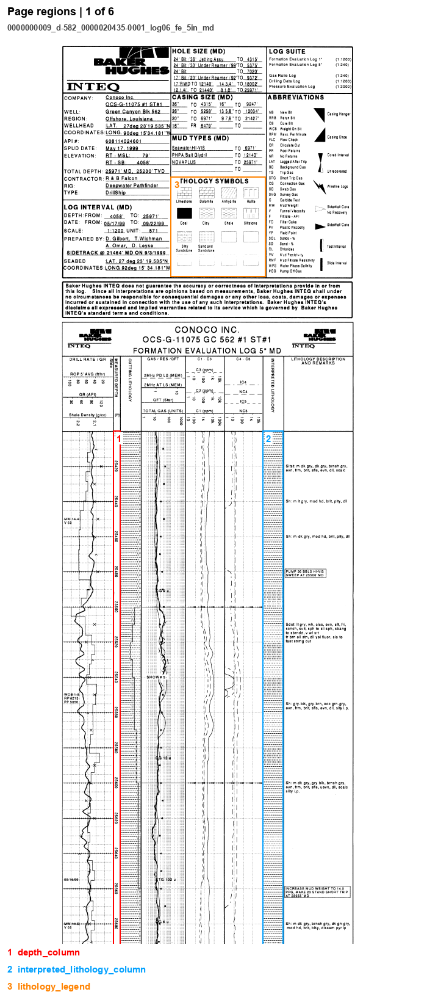

In [9]:
display(Image(filename=r"artifact/img/f03_boxes_1.png", width=700))

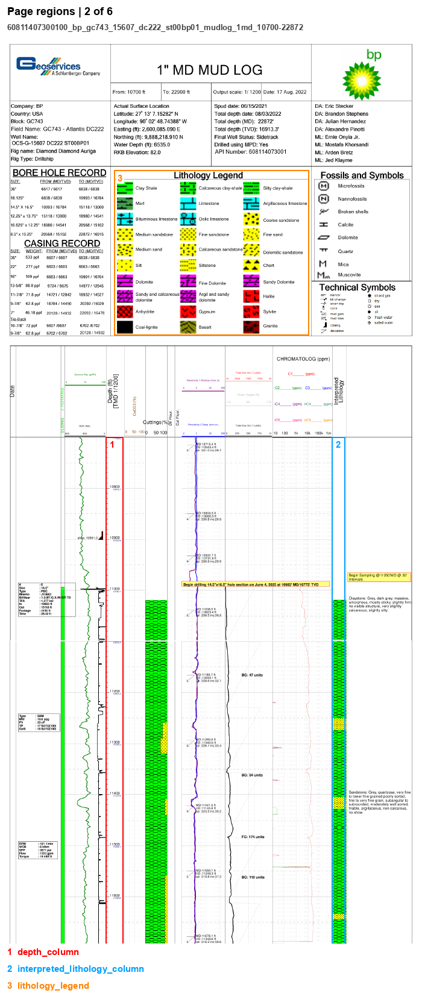

In [10]:
display(Image(filename=r"artifact/img/f03_boxes_2.png", width=700))

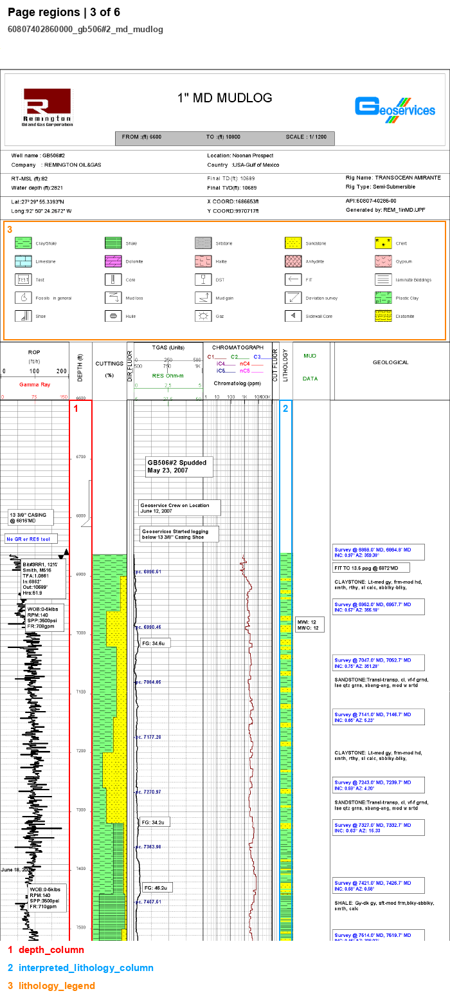

In [11]:
display(Image(filename=r"artifact/img/f03_boxes_3.png", width=700))

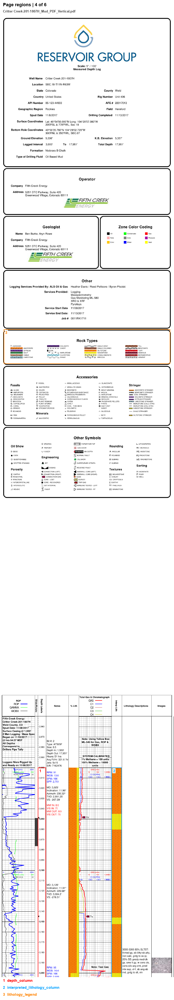

In [12]:
display(Image(filename=r"artifact/img/f03_boxes_4.png", width=700))

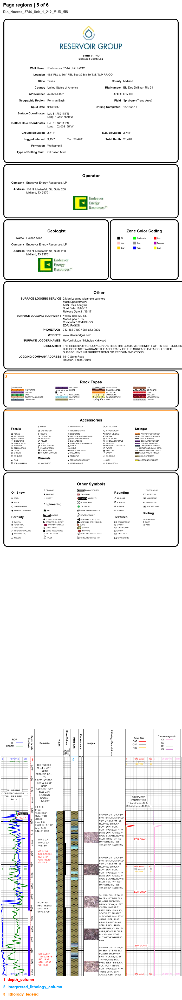

In [13]:
display(Image(filename=r"artifact/img/f03_boxes_5.png", width=700))

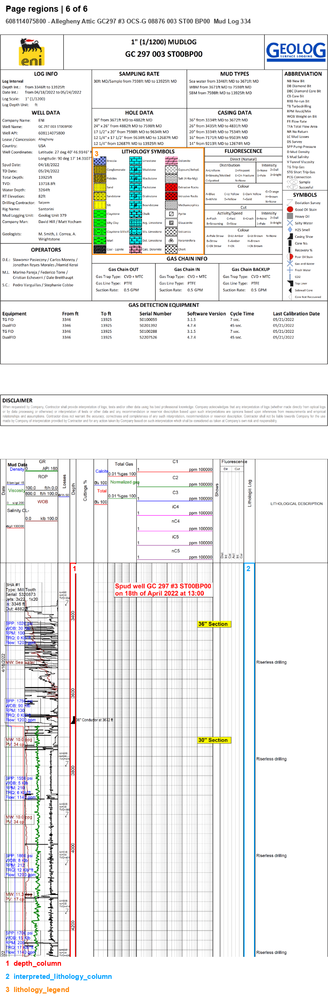

In [14]:
display(Image(filename=r"artifact/img/f03_boxes_6.png", width=700))

## 4. What makes it hard

**Pattern-only rocks: 1-bit logs have no colour at all.**

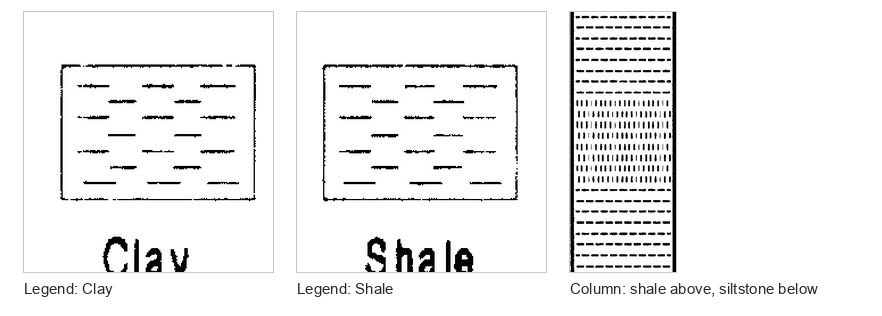

In [15]:
display(Image(filename=r"figs/hard/h1_pattern_only.jpg"))

**Legends mix rocks with modifier and drilling symbols.**

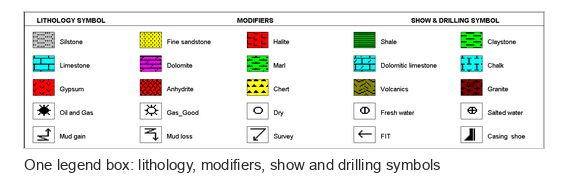

In [16]:
display(Image(filename=r"figs/hard/h2_mixed_legend.jpg"))

**Same colour, different rock.**

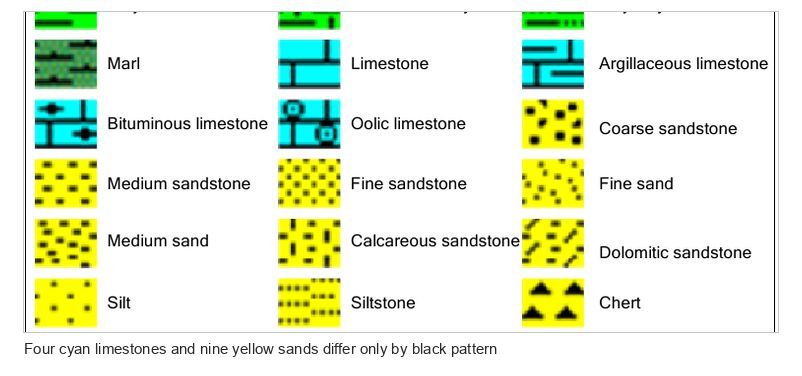

In [17]:
display(Image(filename=r"figs/hard/h3_same_colour.jpg"))

**Legend text a few pixels tall.**

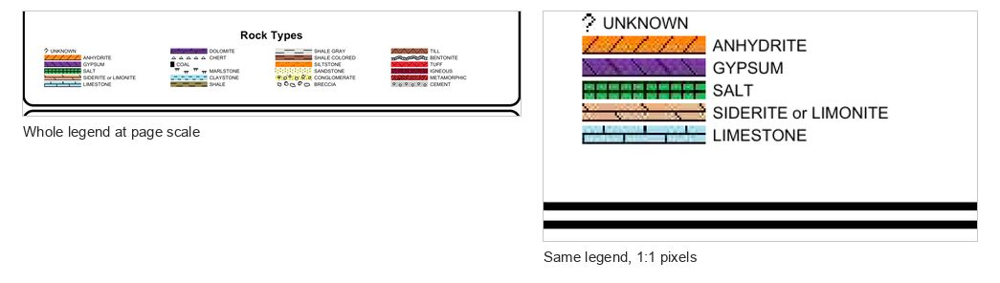

In [18]:
display(Image(filename=r"figs/hard/h4_tiny_text.jpg"))

**Blank stretches and very long single intervals.**

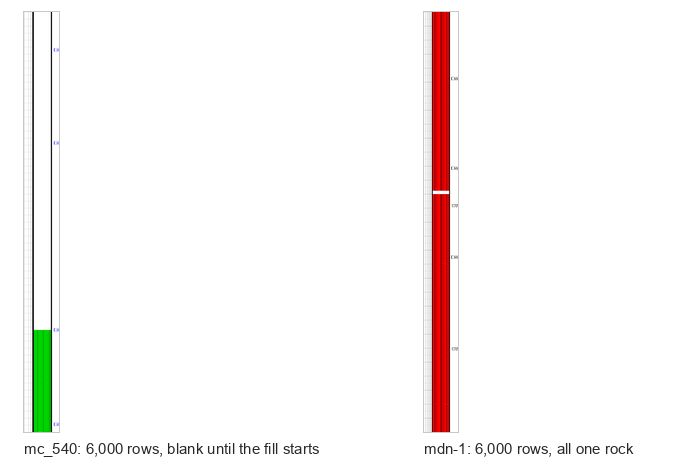

In [19]:
display(Image(filename=r"figs/hard/h5_blank_runs.jpg"))

**Overprinted lines and symbols break runs.**

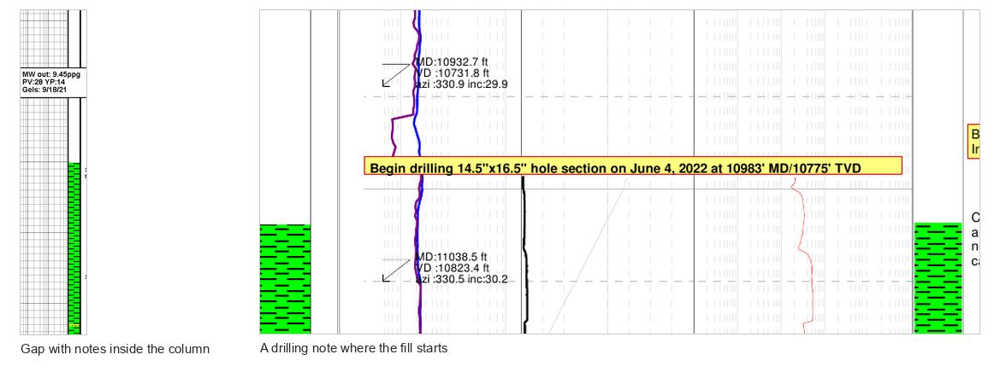

In [20]:
display(Image(filename=r"figs/hard/h6_overprints.jpg"))

## 5. Ground truth and metrics

Three tiers of truth:

| Tier | What | Use |
|---|---|---|
| Gold | log06, supplied | final scoring |
| Silver | two AI labellers (A, B) on 13 test windows | aggregate scores only, never per-log tuning |
| Synthetic | columns stacked from each log's own legend swatches | tuning, exact labels |

Metrics (inside the window, ignoring rows blank in the truth):

* **row_acc**: share of filled rows whose predicted lithology matches.
* **boundary_f1**: interval edges matched one-to-one within `max(4, min(20, 1 % of window))` px.
* **cluster_ari**: adjusted Rand index of `cluster_id` against true lithology.
* **depth_mae_ft**: depth error at matched boundaries.
* **score = row_acc x boundary_f1**, plus seconds, peak RAM, peak GPU memory and API calls.

### How good are AI agents at making datasets?

Both labellers also labelled log06, where we know the truth:

In [21]:
import runpy, io, contextlib
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    cwd = os.getcwd(); runpy.run_path(os.path.abspath("scripts/lab_vs_gold.py"), run_name="__main__"); os.chdir(cwd)
print(buf.getvalue())

A 14 intervals row_acc=0.742 unknown=0.000 bF1=0.625 ['sand and sandstone', 'shale']
B 18 intervals row_acc=0.323 unknown=0.674 bF1=0.944 ['sand and sandstone', 'siltstone', 'unknown']
gold 17 ['sandstone', 'shale', 'siltstone']



They fail in opposite ways. **A** names rocks well (74 % of rows right) but misplaces edges. **B** finds edges well
(boundary F1 0.94) but left 67 % of rows as Unknown. Agents find boundaries well and name black-and-white hatches badly,
so silver labels need a person's check.

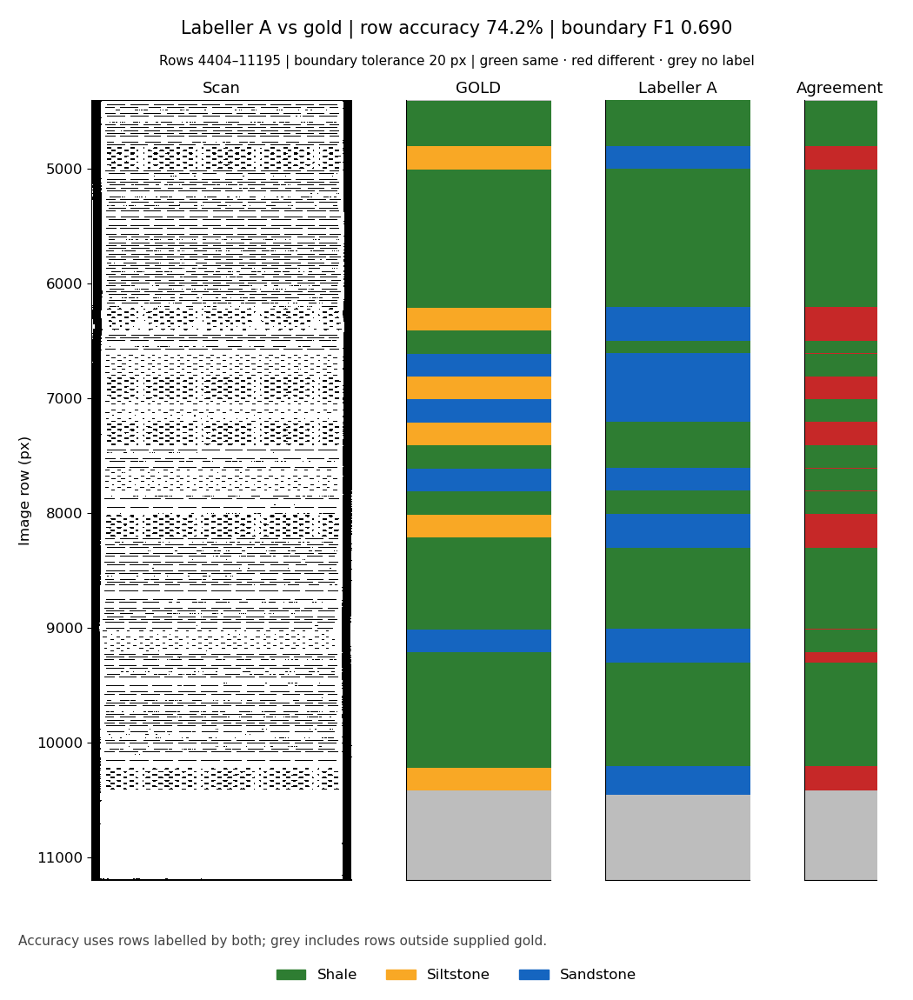

In [22]:
display(Image(filename=r"artifact/img/f04_labeller_vs_gold.png"))

## 6. Shared building blocks

### Legend parser (step zero for every strategy)

Swatches are found as rectangles, paired with OCR labels, and entries under "Modifiers" or "Show and drilling" are marked
as not rock. It found every swatch on the 7 pages checked by eye; remaining slips are OCR spellings such as "Anhydrlte",
"Coarsesandstone" and "SHALEGRAY", so names are matched fuzzily.

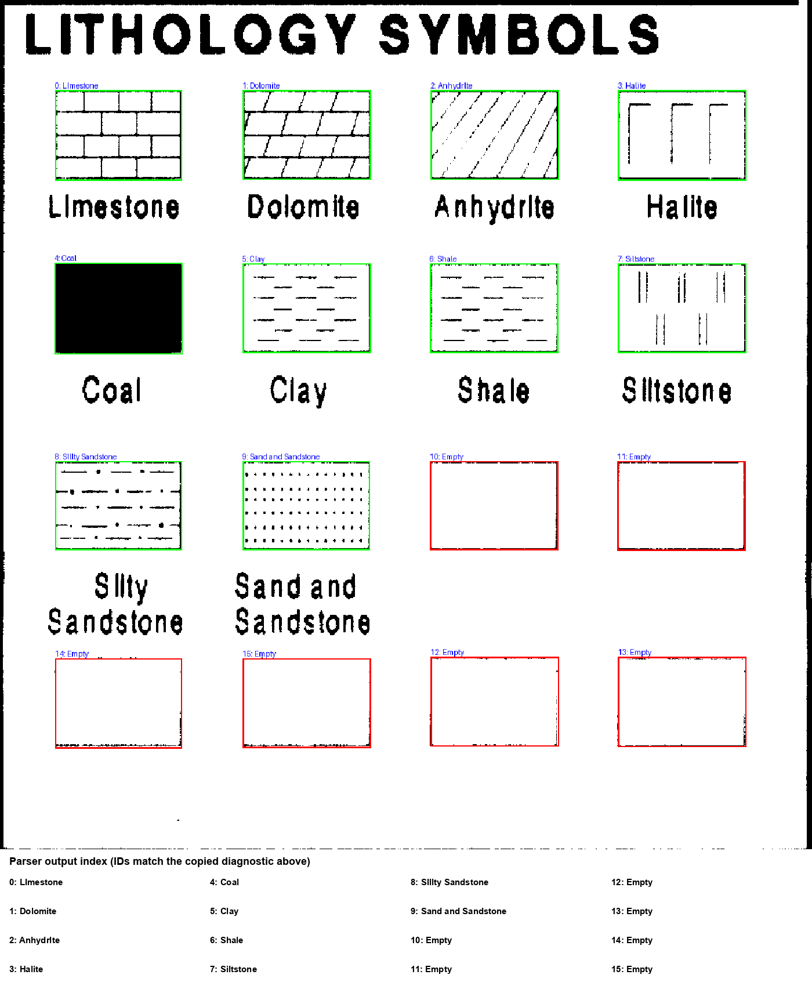

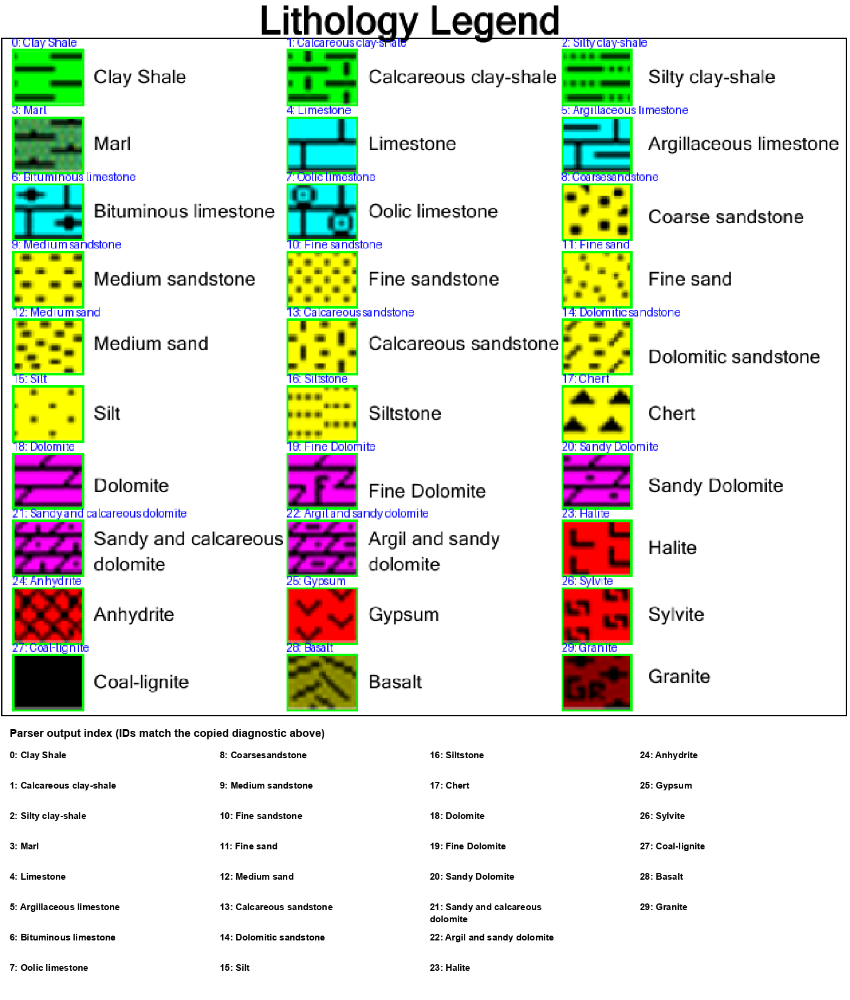

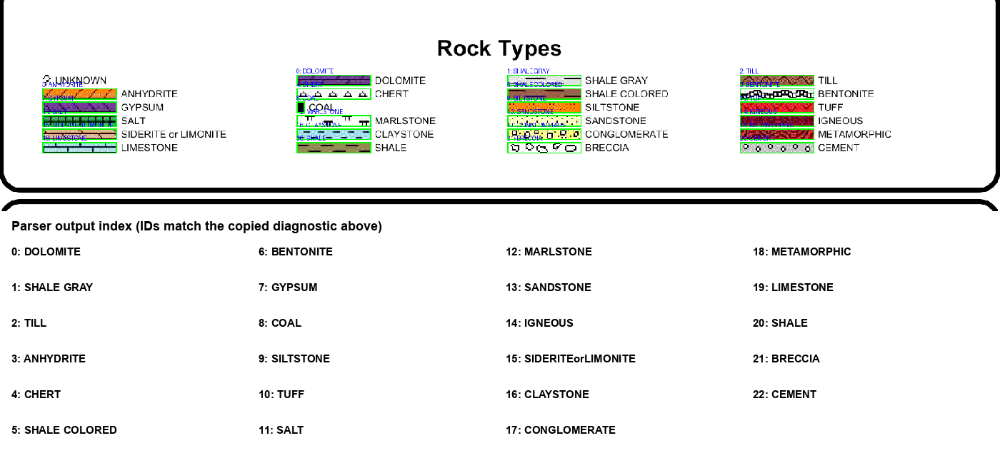

In [23]:
display(Image(filename=r"artifact/img/f05_legend_parse_1.png"))
display(Image(filename=r"artifact/img/f05_legend_parse_2.png"))
display(Image(filename=r"artifact/img/f05_legend_parse_3.png"))

### Depth calibration

RapidOCR reads the numbers in the depth column, then RANSAC fits `depth = a * y + b`.

| Log | ft per px | anchor points | fit error (px) | seconds |
|---|---:|---:|---:|---:|
| log06 | 0.0499 | 12 | 0.68 | 9.2 |
| GB506#2 | 0.4993 | 35 | 0.50 | 15.8 |
| BP GC743 | 0.4999 | 62 | 0.47 | 33.3 |
| Allegheny | 0.4995 | 31 | 2.17 | 18.7 |
| Neptune | 0.3329 | 39 | 1.33 | 21.8 |
| Critter Creek | 0.1333 | 161 | 0.60 | 48.4 |
| Rio Nueces | 0.1000 | 119 | 1.11 | 41.6 |

On log06 row 4409 maps to 25,400.27 ft against the supplied 25,400 ft.

## 7. The strategies, and why each is in the race

All strategies share the loader, legend parser, depth step and scorer, so a score difference comes from the strategy alone.
Each must implement `run(log, window, ctx) -> rows (+ stage images)`. The sketches below show the idea; the full code is in
`bakeoff/strategies/`. Demo images are real runs on real crops.

### S1: Colour runs  (CPU)

Most colour logs paint each rock a flat colour. Read the dominant colour of every pixel row and cut where it changes for long enough.

**Why it is here:** The baseline every other method must beat. Milliseconds a log, no model.

| Strength | Weakness |
|---|---|
| Fastest; exact boundaries on flat fills | Blind on the 9 black-and-white logs; same-colour rocks merge |

```python
col = rgb[:, int(.15*w):int(.85*w)]          # skip the borders
ink = col.max(2) < 60; paper = col.min(2) > 230
dom = mode_colour(col, mask=~ink & ~paper)       # one colour per row
cuts = changes(quantise_lab(dom), min_run=15)
name = nearest_swatch_colour(cluster_colour)
```
**Measured:** 0.27 s for 6,000 rows of the bp_gc743 colour log.

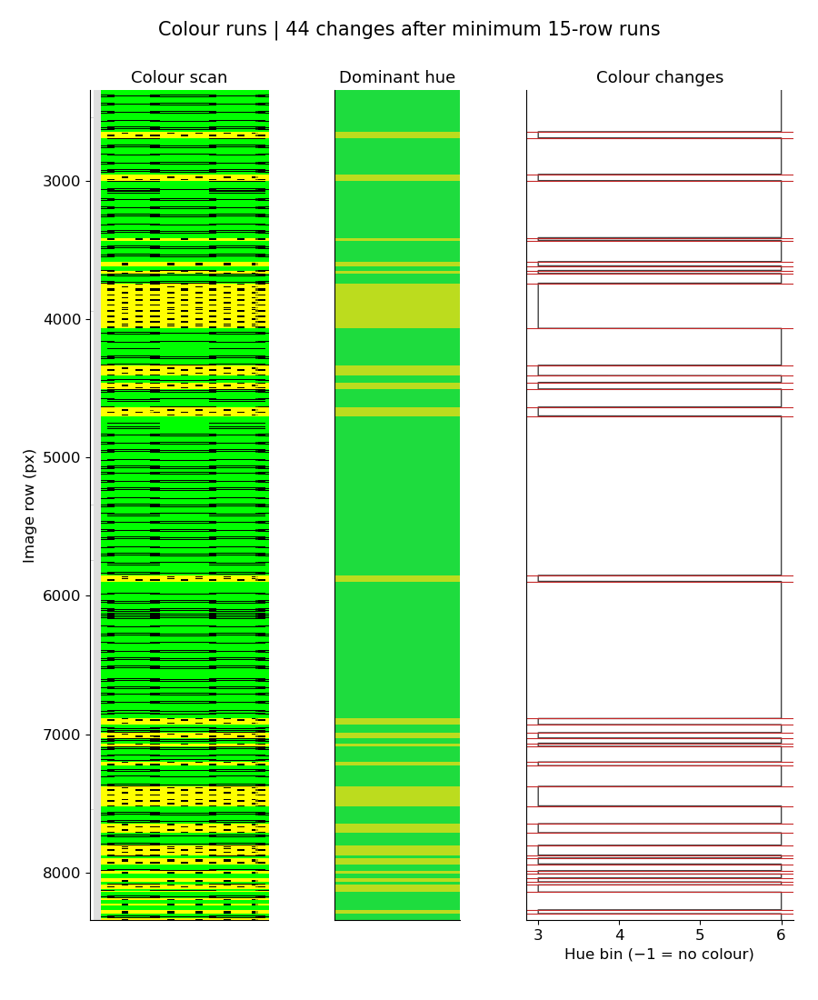

In [24]:
display(Image(filename=r"artifact/img/d_s1_colour_runs.png"))

### S2: Hand-made features + change points  (CPU)

Describe each row by ink fraction, horizontal and vertical stroke density, colour and pattern period, then let PELT find where that signal shifts.

**Why it is here:** Works on colour and hatch-only logs alike, and its segment() is reused by S8, S9 and S10 for boundaries.

| Strength | Weakness |
|---|---|
| Good boundaries everywhere; explainable | Naming two similar hatches is weak |

```python
f = np.stack([ink, sobel_y_density, sobel_x_density,
              lab_mean, autocorr_period], 1)
f = uniform_filter1d(f, 40, axis=0)
cuts = ruptures.Pelt(model="rbf").fit(zscore(f)).predict(pen=8)
clusters = AgglomerativeClustering(distance_threshold=1.5).fit(seg_means)
```
**Measured:** boundary F1 0.86 (all 6 true boundaries found, 2 extra), 3.6 s.

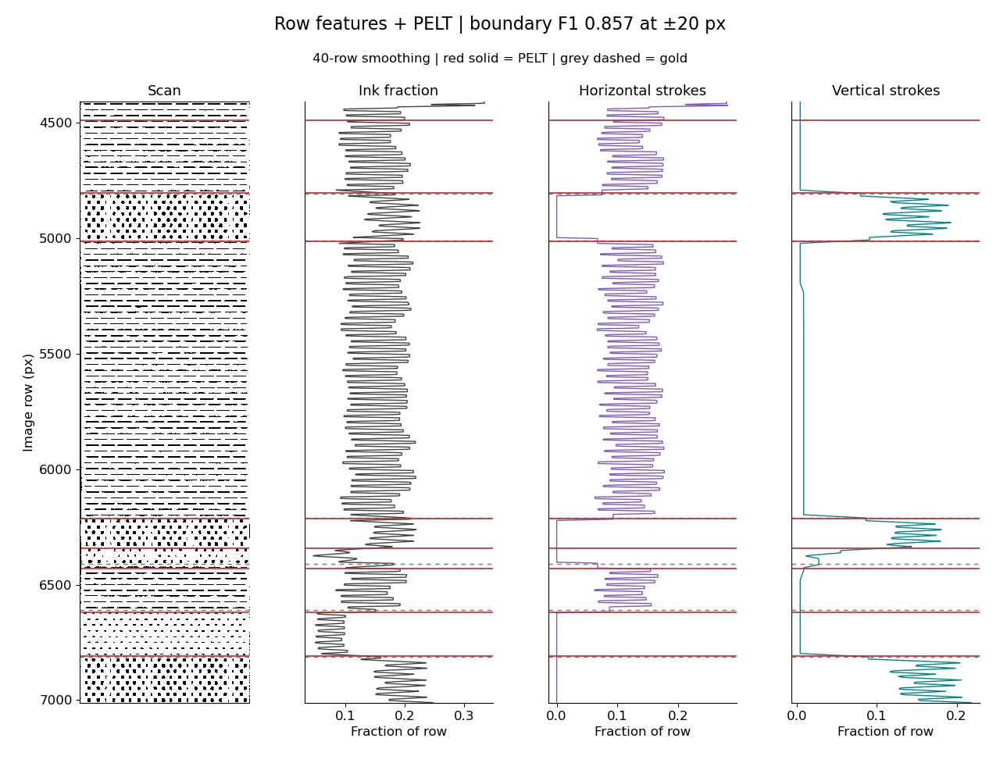

In [25]:
display(Image(filename=r"artifact/img/d_s2_features_pelt.png"))

### S3: Template matching  (CPU)

Cut each legend swatch, slide it down the column, score every tile with normalised cross-correlation and keep the best match.

**Why it is here:** The most literal reading of the task: the legend is the answer key, so match against it.

| Strength | Weakness |
|---|---|
| Names come straight from the legend; good on 1-bit hatches | Breaks when the swatch is drawn at another scale or phase |

```python
for e in rock_swatches:
    tpl = tile(strip_border(e.swatch), h=64)
    for s in (0.8, 1.0, 1.25):
        score[e.id] = max(score[e.id],
            cv2.matchTemplate(column, rescale(tpl, s), cv2.TM_CCOEFF_NORMED))
label = argmax(score, axis=0); merge_runs(label)
```
**Measured:** best correlation only 0.04 to 0.08, so raw NCC barely separates the hatches. It needs scale and phase search before it is useful.

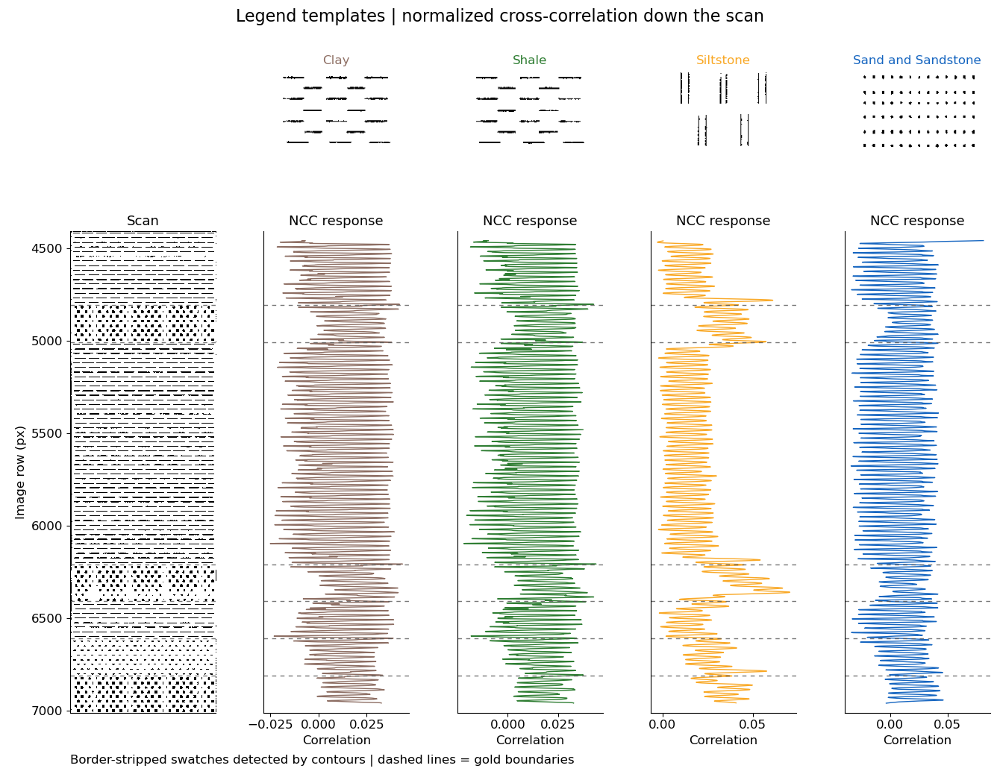

In [26]:
display(Image(filename=r"artifact/img/d_s3_template_ncc.png"))

### S4: k-means + Viterbi smoothing  (CPU)

Cut the column into 20-row tiles, cluster their texture features, then smooth along depth so one odd tile cannot create a fake interval.

**Why it is here:** Clustering is half the score (cluster_id), and smoothing removes the speckle that ruins boundary F1.

| Strength | Weakness |
|---|---|
| Robust to noise; no legend needed to group | Must guess k; naming is a separate step |

```python
X = [lab_hist(t) + lbp_hist(t) + [ink(t)] for t in tiles]
k = best_silhouette(X, range(2, 11))
raw = KMeans(k).fit_predict(X)
clean = viterbi(raw, p_stay=0.98)     # long runs win
cuts = refine_to_row(clean)
```
**Measured:** Viterbi cut 48 label changes to 1 and raised row accuracy from 0.65 to 0.77, but it also merged short Sandstone beds.

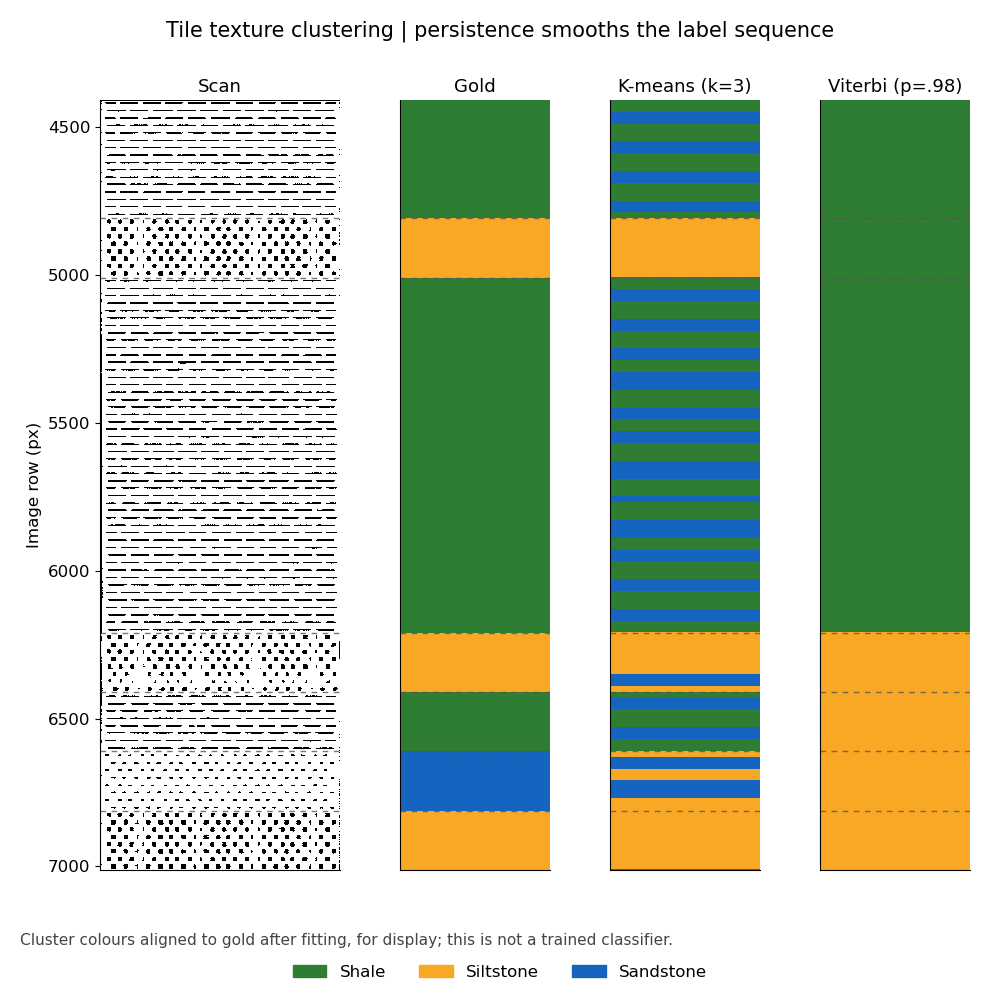

In [27]:
display(Image(filename=r"artifact/img/d_s4_kmeans_viterbi.png"))

### S5: DINOv2 embeddings  (GPU)

A self-supervised vision model turns each 64-row tile into a vector. Big jumps between neighbouring vectors are boundaries.

**Why it is here:** Downloaded, pretrained, no training: tests whether general vision features already separate rock symbols.

| Strength | Weakness |
|---|---|
| Sees texture, not just colour; strong grouping | Swatches are tiny; 88 MB model; needs a GPU to be quick |

```python
m = AutoModel.from_pretrained("facebook/dinov2-small").cuda()
E = m(pixel_values=tiles_224).pooler_output     # one vector per tile
d = 1 - cosine(E[1:], E[:-1])                   # change along depth
cuts = find_peaks(d, prominence=.15)
name = argmax(cos(seg_mean, swatch_embeds) + a*lab_sim)
```
**Measured:** 3.1 s, 242 MB peak GPU. Distance peaks are dense, so they need PELT or a prominence threshold on top.

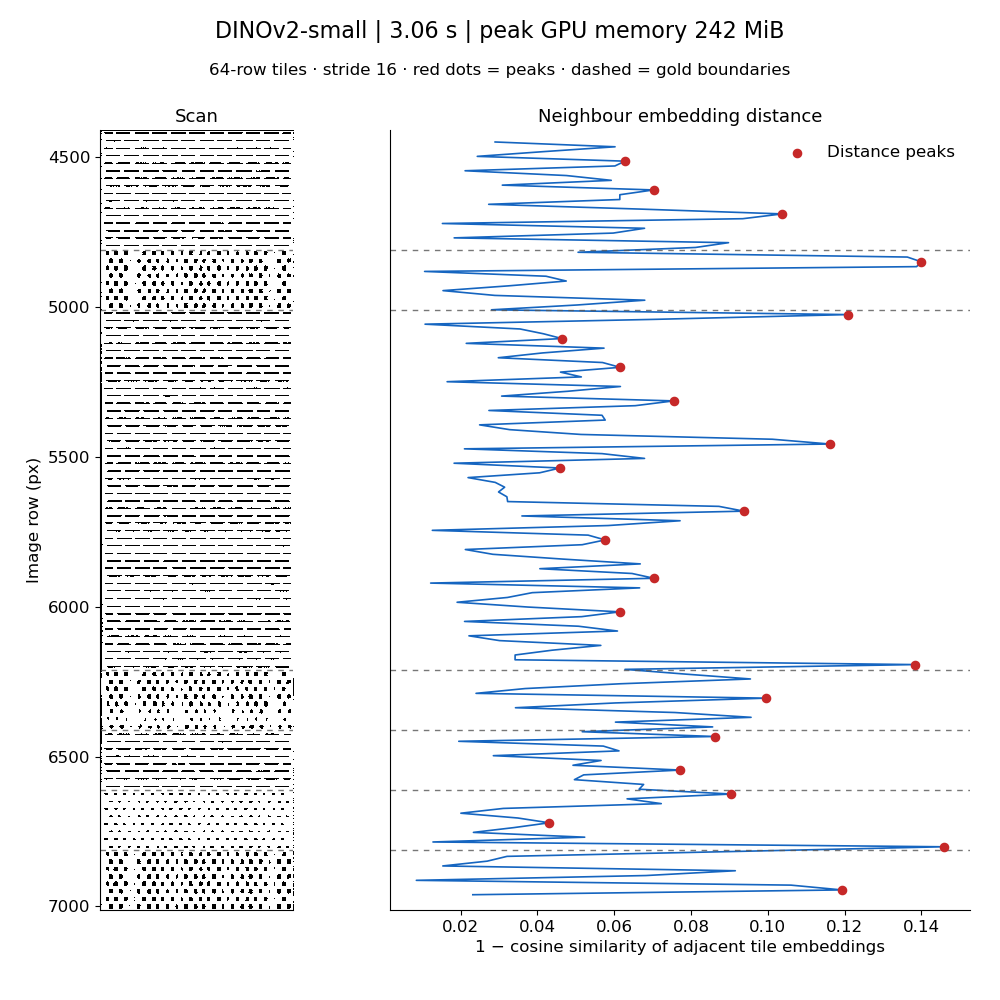

In [28]:
display(Image(filename=r"artifact/img/d_s5_dinov2.png"))

### S6: SigLIP image + text  (GPU)

Same tiles, but SigLIP also scores text such as 'a lithology symbol for sandstone', so the label words help with naming.

**Why it is here:** Checks whether a downloadable image-text model knows what rock symbols look like.

| Strength | Weakness |
|---|---|
| Uses the label text, not only the swatch | Hatch-only symbols mean little to it |

```python
img = siglip.get_image_features(tiles)
txt = siglip.get_text_features(
    [f"a geological lithology symbol for {e.label}" for e in rocks])
score = w*cos(img, swatch_img) + (1-w)*cos(img, txt)
```

### S7: CNN trained on synthetic columns  (GPU)

Stack this log's own legend swatches into fake columns with noise, train a small CNN for 25 s, then classify the real column.

**Why it is here:** Training data for free: the legend is a labelled sample of every class this log can contain.

| Strength | Weakness |
|---|---|
| Only predicts names in this legend | Slowest local option; synthetic-to-real gap |

```python
X, y = synth.make(log, n=400, jitter=True, jpeg=True, lines=True)
net = timm.create_model("resnet18", num_classes=len(rocks)).cuda()
train(net, X, y, seconds=25)
labels = viterbi(net(column_tiles).softmax(1))
```

### S8: JEV typed choice (Typesafe)  (API)

Find boundaries with S2, then send one crop per cluster to JEV with a choice question over this log's legend names.

**Why it is here:** One call per cluster, not per row: about 5 calls a log, with typed probabilities we can threshold.

| Strength | Weakness |
|---|---|
| Fast API (about 0.4 s); calibrated choices | Needs network and a key; paid |

```python
ans = jev(state={"crop": "img1"}, assets={"img1": png_512(crop)},
          questions={"lith": {"type": "choice",
              "instructions": "Which legend pattern fills this column?",
              "criteria": {e.label: describe(e) for e in rocks}}})
name = ans["lith"]["choice"]            # + probabilities
```
**Measured:** 2 of 3 right in 0.33 to 0.39 s a call. The Sandstone crop came back as Siltstone at 0.83 confidence, so confidence alone cannot be trusted.

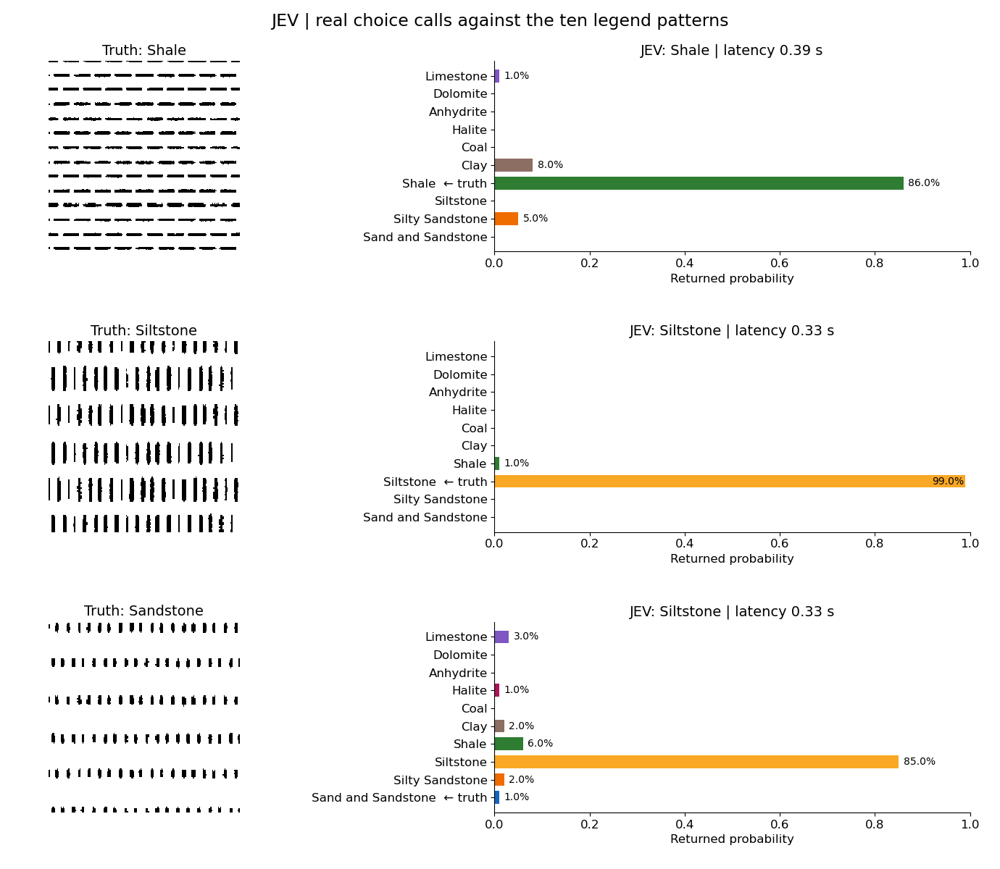

In [29]:
display(Image(filename=r"artifact/img/d_s8_jev.png"))

### S9: Vision LLM (Terra)  (API)

Show a general vision LLM the cluster crop next to the numbered legend and ask for the swatch number, as a person would.

**Why it is here:** The human way of doing it. Shows how far a general multimodal model gets with no task code.

| Strength | Weakness |
|---|---|
| Reads odd layouts and tiny text | Tens of seconds a call; answers vary |

```python
png = side_by_side(upscale(crop), numbered_legend(rocks))
out = run(["codex", "exec", "-m", "gpt-6.1-terra", "-i", png,
           'Which numbered swatch matches the left strip? JSON {"n": int}'])
name = rocks[json.loads(out)["n"]].label
```

### S10: Hybrid: local first, API on ties  (GPU + API)

S2 boundaries, DINOv2 + colour naming, and JEV only when the top two candidates are too close to call.

**Why it is here:** Spends API calls only where local models are unsure: the expected accuracy-per-second winner.

| Strength | Weakness |
|---|---|
| Best expected accuracy for its cost | Most moving parts to tune |

```python
s = .6*cos(dino(seg), dino(swatch)) + .4*lab_sim(seg, swatch)
top2 = s.topk(2)
if top2[0] - top2[1] < margin:          # tuned on synthetic
    name = jev_choice(seg_crop, candidates=top2.labels)
else:
    name = top2.label[0]
```

### S11: FFT hatch + Lab swatch matching, with an Unknown option  (CPU)

Added from the research (rank 2). Plain template matching scored only 0.04 to 0.08 correlation on log06 because the
column's hatch is shifted and rescaled relative to the swatch. The 2-D FFT magnitude ignores where the pattern starts,
so comparing pooled spectra (plus ink fraction and colour) is phase-invariant; a small top-2 margin returns "Unknown".

```python
def spectrum(grey):
    f = np.abs(np.fft.fftshift(np.fft.fft2((grey - grey.mean()) * hann2d(grey.shape))))
    return pool_radial_angular(f, r_bins=12, a_bins=8, scale=dominant_period(f))
dist = [w_fft * l1(spectrum(win), spectrum(sw)) + w_ink * abs(ink(win) - ink(sw))
        + w_lab * lab_hist_dist(win, sw) for sw in rock_swatches]
name = label[argmin(median(dist over windows))] if margin > tau else "Unknown"
```

### B1 (bonus): find the boxes without the annotation

```python
ans = jev(assets={"page": thumb_png},
          questions={"legend": {"type": "box", "instructions": "the lithology legend panel"}})
coarse = to_pixels(ans["legend"]["box"], page_size)
x0, x1 = snap_to_ruled_lines(coarse, vertical_lines(page))
```
A first test on 3 pages: JEV alone found the legend with overlap 0.47 to 0.73 but mostly missed the columns, which are a
few pixels wide on a 1,024 px thumbnail. Snapping to ruled lines at native width does the rest.

**JEV details learned the hard way:** set the header `TypeSafe-Danger-Zone-Images: true`; images go in `assets` and are
named from `state`; each side must be 512 to 1024 px; sent as base64 text inside `state`, the image is read as text.

## 8. Trade-offs at a glance

| Strategy | Hardware | Speed | Cost per log | Best on | Weak on |
|---|---|---|---|---|---|
| S1 colour runs | CPU | 0.27 s measured | 0 | flat colour logs | 1-bit logs, same-colour rocks |
| S2 features + PELT | CPU | 3.6 s measured | 0 | boundaries everywhere | naming near-identical patterns |
| S3 template matching | CPU | 0.7 s measured | 0 | exact-scale swatches | scale or phase mismatch |
| S4 k-means + Viterbi | CPU | 3.9 s measured | 0 | noisy scans | picking k, thin beds |
| S5 DINOv2 | GPU | 3.1 s measured | 0 | texture changes | tiny swatches |
| S6 SigLIP | GPU | 2 to 10 s est. | 0 | clear rock names | hatch-only logs |
| S7 synthetic CNN | GPU | about 30 s est. | 0 | names limited to this legend | slowest local option |
| S8 JEV | API | 0.33 s a call measured | one call per cluster | naming from a picture | confident misses |
| S9 Terra | API | tens of s a call est. | ChatGPT plan | reads like a person | slow, varies |
| S10 hybrid | GPU + API | 5 to 15 s est. | calls on ties only | accuracy per second | most moving parts |
| S11 FFT matching | CPU | seconds est. | 0 | shifted hatches | very small swatches |

Measured times are from demo windows of 2,600 to 6,000 rows; section 10 has the bake-off's own numbers.

## 9. Research: how to do each step better, cheaper and faster

Eight research agents (one per pipeline step) searched papers, GitHub and model cards; their notes are in `research/r*.md`.
A ninth merged them, spot-checked the key claims against their sources, and ranked the upgrades. Notes: the depth RANSAC
fit (its rank 1) is already in the shared harness, and none of the sources tested anything on mud logs, so the bake-off
decides. The merged report follows verbatim.



The first three upgrades below total roughly 15 hours, leaving time to integrate and evaluate. Rankings are engineering judgments, not measured gains: none of the sources establishes performance on these 51 logs. `r1.txt` was absent; the identical task context in `r1_layout.txt` was used.

### Spot-check: 10 consequential claims

VERIFIED means the cited source supports the specific claim, not that its benchmark transfers to mud logs. Model files were listed online, not downloaded or executed.

| Claim in notes | Check |
|---|---|
| R1: PP-DocLayout-S 70.9 mAP@0.5, Apache-2.0 | **VERIFIED**: [card](https://huggingface.co/PaddlePaddle/PP-DocLayout-S) reports 70.9 on its 500-image document dataset and lists the licence. |
| R8: Florence-2-large-ft TextVQA 81.5 | **WRONG**: [Microsoft's table](https://huggingface.co/microsoft/Florence-2-large) reports 73.5 TextVQA and 81.7 VQAv2. |
| R1: Qwen2.5-VL-3B licence is non-commercial | **VERIFIED**: the checkpoint's [licence](https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct/blob/main/LICENSE) limits use to research/evaluation without a commercial licence. |
| R8: Qwen2.5-VL-3B DocVQA 93.9 on its official card | **UNVERIFIABLE**: [checkpoint card](https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct) does not show that number; this does not disprove it elsewhere. |
| R8: Phi-4 multimodal DocVQA 93.2 | **VERIFIED**: [Microsoft card](https://huggingface.co/microsoft/Phi-4-multimodal-instruct) reports 93.2; vendor benchmark, not hatch recognition. |
| R8: SmolVLM2-2.2B DocVQA 79.98, Apache-2.0 | **VERIFIED**: both appear on its [card](https://huggingface.co/HuggingFaceTB/SmolVLM2-2.2B-Instruct). |
| R7: `facebook/dinov2-small` downloadable, Apache-2.0 | **VERIFIED**: [model card](https://huggingface.co/facebook/dinov2-small) lists the checkpoint, files and licence; local download untested. |
| R2: `ruptures` licence unknown | **VERIFIED** as now resolved: [upstream](https://github.com/deepcharles/ruptures) specifies BSD-2-Clause. |
| R1: DocLayout-YOLO inference repository AGPL-3.0 | **VERIFIED**: [repository](https://github.com/opendatalab/DocLayout-YOLO) lists AGPL-3.0; checkpoint terms are separate. |
| R6: pyLogDigitizer source is AGPL-3.0 | **VERIFIED** for the [repository](https://github.com/GeoLarryLai/pyLogDigitizer); R5 reports conflicting PyPI metadata, so resolve before reuse. |

### Ranked upgrades

Steps: 1 boxes, 2 legend, 3 boundaries, 4 grouping, 5 naming, 6 depth, 7 efficiency. Hours are estimates; arrows denote hypothesized task gains. Evidence is the cited note's method/source, not a measured gain. Rank accounts for impact, implementation time, dependencies and the optional nature of B1.

| Rank | Upgrade | Step | Improves | Expected gain and evidence | Hours | Risk |
|---:|---|---|---|---|---:|---|
| 1 | Sparse numeric OCR + tick-checked RANSAC | 6 | S10 | Accuracy ↑: robust outlier fitting, R5/R6; no log benchmark | 4–5 | False coherent scale |
| 2 | FFT hatch + Lab swatch matching, reject unknown | 5 | S1, S3, S10 | Accuracy ↑ for phase-shifted same-colour patterns, R3/R6 | 5–6 | Tiny swatches, overprint |
| 3 | Legend geometry + OCR pairing | 2 | S8, S9, S10 | Accuracy ↑ and calls ↓: row geometry, R4 | 4–5 | Nonrectangular symbols |
| 4 | Batched FP16, cache swatch embeddings | 5, 7 | S5, S6 | Speed ↑, cost ↓: reuse existing encoders, R7 | 2–4 | FP16 ranking drift |
| 5 | Bounded TIFF bands and native coordinates | 1–7 | S1–S10, B1 | RAM ↓; speed potentially ↑: demand-driven decode, R7 | 3–5 | Compressed-strip I/O |
| 6 | Confidence-gated existing JEV | 2, 5 | S8–S10 | Calls/cost ↓: one representative per ambiguous cluster, R7 | 2–3 | Confident cheap-stage errors |
| 7 | Multiscale LBP/Gabor + PELT | 3 | S1, S2, S4 | Boundary accuracy ↑ for hatches: texture descriptors, R2 | 3–6 | Lines, thin beds |
| 8 | DINO patch prototypes + texture voting | 5 | S5, S10 | Accuracy ↑: local motif votes, R3 | 2–5 | Patch resolution |
| 9 | HDBSCAN with unknown/noise | 4 | S4, S10 | Accuracy ↑: avoids fixed k, R2 | 2–4 | Singleton classes |
| 10 | Scattering features + L2 PELT | 3–4 | S2, S4 | Accuracy ↑: orientation/frequency features, R2 | 6–10 | Windows setup, runtime |
| 11 | Rule proposals + JEV tie-break | 1 | B1, S8 | Box recall ↑: native-width geometry, R1 | 6–10 | Unruled columns; bonus only |
| 12 | PP-OCRv5 on difficult crops | 2, 6 | S10 | Accuracy ↑: vendor 85.25% English recognition, R4; domain differs | 3–5 | Paddle Windows/CUDA |

### Build next

The harness is not present in this research folder. Filenames below are proposed: inspect its registry and existing data contracts first, then register the indicated IDs without altering baselines. Commands must be run separately with `--set synthetic` and `--set eval`; `--gt gold` is evaluation only. Retain original y coordinates and the required interval schema.

1. **`depth_ransac`** — Add `harness/strategies/depth_ransac.py`, wrapping S10; reuse RapidOCR/EasyOCR, add `numpy`, `opencv-python`, `scikit-learn`. OCR native-resolution depth bands, record numeric anchors and global y; find nearby tick lines. Fit `RANSACRegressor` for depth versus y, refit inliers, check increasing depth, tick spacing and at least three anchors; report residuals and unknown depth on failure. Test `python -m harness.run --strategy depth_ransac --set synthetic --gt gold` and repeat with `eval`. Compare endpoint depth error, inlier overlays and runtime against S10; test bad digits and scale breaks.

2. **`fft_legend`** — Add `harness/strategies/fft_legend.py`, wrapping S10 boundaries; use `numpy`, `scipy`, `opencv-python`. Crop swatch interiors and several interval windows, preserve scale and orientation, remove obvious borders, Hann-window FFT magnitudes, compare directional frequency bins plus ink fraction and Lab colour; suppress colour for 1-bit. Aggregate by median, expose top-two margin and unknown. Test `python -m harness.run --strategy fft_legend --set synthetic --gt gold` and repeat with `eval`; compare S1/S3/S10 depth-weighted accuracy, per-class accuracy, unknown rate and phase-shift/overprint cases.

3. **`legend_pairs`** — Add `harness/strategies/legend_pairs.py`, wrapping S10; reuse existing OCR plus `opencv-python` and `scipy`. OCR the provided legend at native and 3× scales; find rectangle and non-text component candidates, merge multiline labels, pair using vertical alignment and Hungarian assignment with unmatched options. Keep boxes, raw text, confidence and rock/modifier/unknown; send ambiguous items to existing JEV only. Test `python -m harness.run --strategy legend_pairs --set synthetic --gt gold` and repeat with `eval`; audit pairing overlays, rock/modifier errors and calls against S10.

Evaluate synthetic cases separately from the single 17-interval labelled example; manually inspect unseen monochrome, palette, blank and same-colour logs. Report boundary error, depth-weighted accuracy, wall time and peak RAM/VRAM. Do not tune on the entire evaluation set.

### Disagreements and decisions

- **Local VLM as primary versus adjudicator:** R8 prefers Qwen; R4/R7 favour OCR and cheap matching first. The latter has the stronger task fit: document QA scores do not validate hatch matching, and Qwen's checkpoint has research-only terms. Compare per-cluster only if time remains.
- **Scattering versus conventional texture:** R2 favours scattering; R3/R6 favour FFT/LBP. Neither has target-domain evidence. Start FFT for direct phase-tolerant legend matching, then test scattering for boundaries if time remains; these address different steps.
- **Whole-page Florence proposals versus native bands:** R8 suggests a downscaled page for proposals; R1's geometry supports native-width bands. A 63-pixel strip becomes about 1.3 pixels on a 50,000-to-1,024-pixel reduction, so full-page proposals are unreliable for narrow tracks.
- **TIFF memmap:** R5 suggests it for uncompressed/tiled images; R7 correctly limits direct mapping to compatible contiguous uncompressed layouts. Inspect each TIFF; compressed or tiled data may need segment selection and codecs.
- **OCR engine:** R5 proposes PP-OCR first; R6 reuses existing OCR. With Windows setup and no domain comparison, reuse existing engines plus robust calibration first; A/B PP-OCR on failures.

## 10. Live bake-off results

This cell reads whatever the strategy runs have written so far (`bakeoff/out/<strategy>/metrics.json`). Rerun it to refresh.

In [30]:
rows = []
for p in sorted(glob.glob("bakeoff/out/*/metrics.json")):
    if "_dummy" in p: continue
    m = json.load(open(p, encoding="utf8"))
    logs = m.get("logs", {})
    items = logs.items() if isinstance(logs, dict) else [(x.get("log"), x) for x in logs]
    for log, r in items:
        if not isinstance(r, dict): continue
        rows.append({"strategy": m.get("strategy"), "set": m.get("set"), "gt": m.get("gt"), "log": str(log)[:40],
                     **{k: r.get(k) for k in ("score", "row_acc", "boundary_f1", "cluster_ari", "seconds", "api_calls", "error")}})
res = pd.DataFrame(rows)
if res.empty:
    print("No strategy metrics yet.")
else:
    display(res[res["gt"] == "gold"].sort_values("score", ascending=False).round(3) if "gt" in res else res)
    display(res.groupby(["strategy", "set", "gt"])[["score", "row_acc", "boundary_f1", "cluster_ari", "seconds"]].mean().round(3))

,strategy,set,gt,log,score,row_acc,boundary_f1,cluster_ari,seconds,api_calls,error
13,s01_colour_runs,eval,gold,0000000009_d-582_0000020435-0001_log06_f,0.006,0.102,0.058,0.253,0.964,0,None
74,s06_siglip,eval,gold,0000000009_d-582_0000020435-0001_log06_f,0.003,0.014,0.207,0.317,14.001,0,None
0,b01_jev_boxes,eval,gold,0000000009_d-582_0000020435-0001_log06_f,0.000,0.000,0.552,0.437,1.156,0,None
26,s02_features_pelt,eval,gold,0000000009_d-582_0000020435-0001_log06_f,0.000,0.000,0.848,0.377,3.641,0,None
39,s03_template_match,eval,gold,0000000009_d-582_0000020435-0001_log06_f,0.000,0.000,0.091,0.044,3.278,0,None
...,...,...,...,...,...,...,...,...,...,...,...
131,s11_fft_legend,eval,gold,608114075800 - Allegheny Attic GC297 #3,NaN,NaN,NaN,NaN,4.567,0,None
132,s11_fft_legend,eval,gold,60817411400100_mc761_1_st1_mudlog_1md_17,NaN,NaN,NaN,NaN,3.111,0,None
133,s11_fft_legend,eval,gold,60818400650000_at0574_4_neptune_1inch_tv,NaN,NaN,NaN,NaN,15.525,0,None
134,s11_fft_legend,eval,gold,Critter Creek 201-1807H_Mud_PDF_Vertical,NaN,NaN,NaN,NaN,3.511,0,None


,,,score,row_acc,boundary_f1,cluster_ari,seconds
strategy,set,gt,,,,,
b01_jev_boxes,eval,gold,0.000,0.000,0.552,0.437,1.252
s01_colour_runs,eval,gold,0.006,0.102,0.058,0.253,0.826
s02_features_pelt,eval,gold,0.000,0.000,0.848,0.377,4.434
s03_template_match,eval,gold,0.000,0.000,0.091,0.044,4.564
s04_kmeans_viterbi,eval,gold,0.000,0.000,0.429,0.637,1.971
s05_dinov2,eval,gold,0.000,0.000,0.774,0.629,4.644
s06_siglip,eval,gold,0.003,0.014,0.207,0.317,9.140
s07_synth_cnn,eval,gold,0.000,0.000,0.615,0.416,8.663
s08_jev,eval,gold,0.000,0.000,0.500,0.318,4.581


Each strategy's pipeline figure on log06 (page with boxes, prediction vs truth vs error strip, legend, and its stages):

**s01_colour_runs**

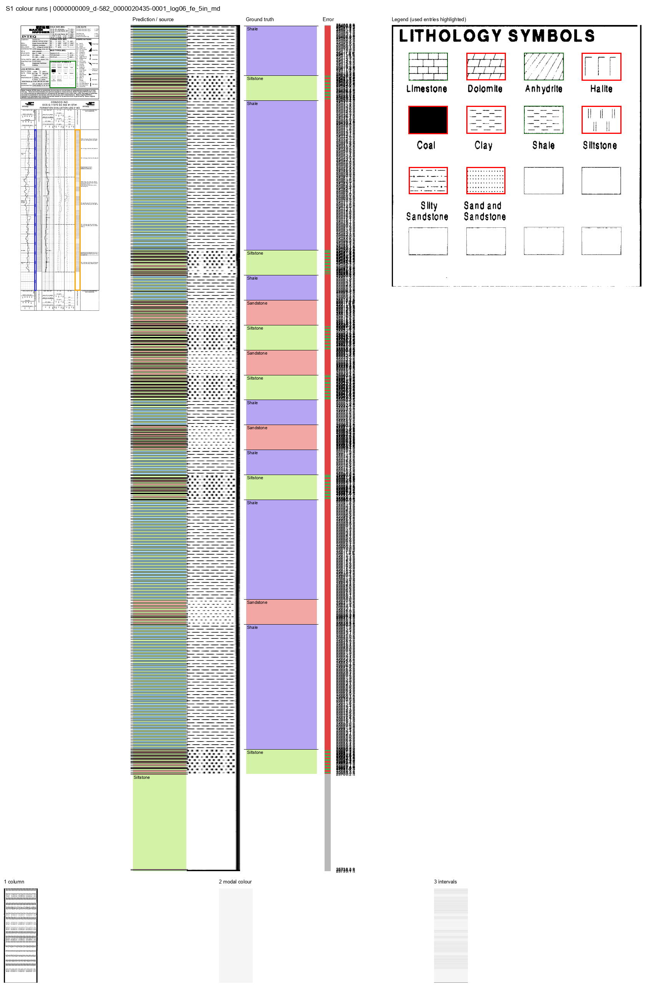

**s02_features_pelt**

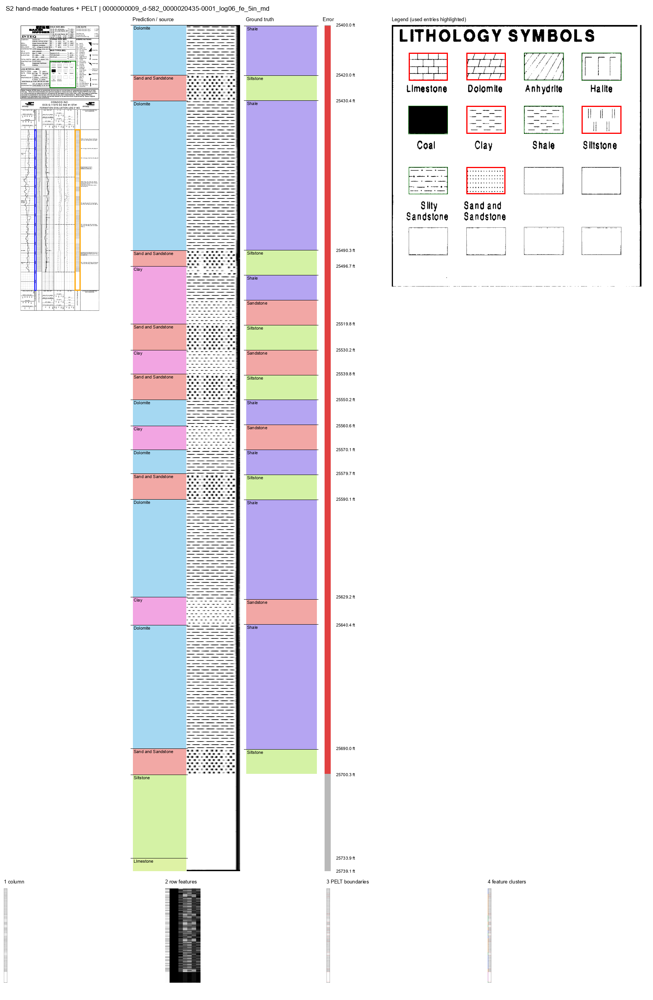

**s03_template_match**

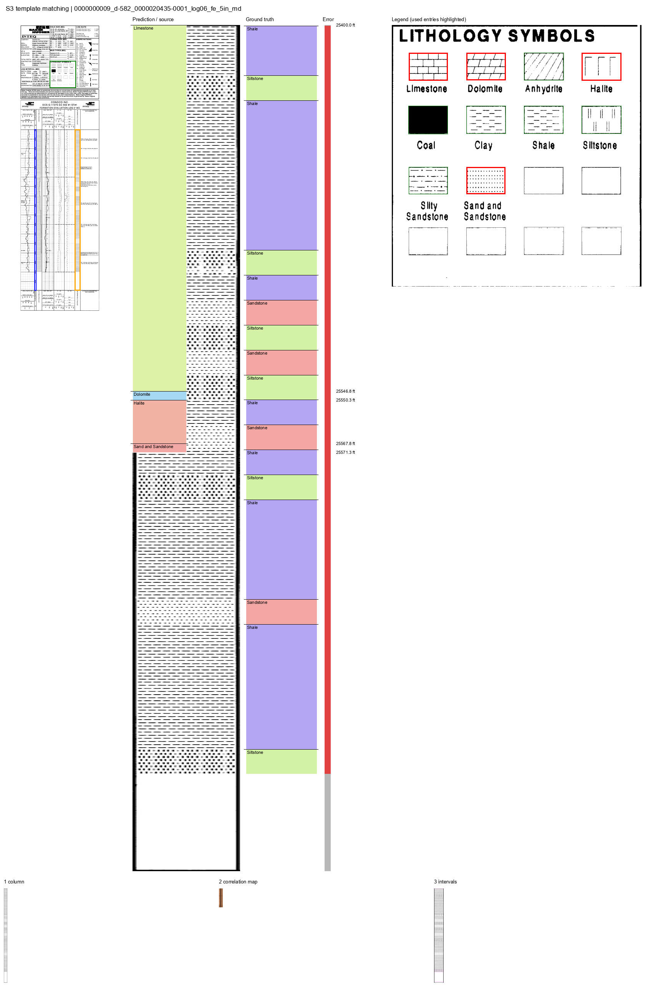

**s04_kmeans_viterbi**

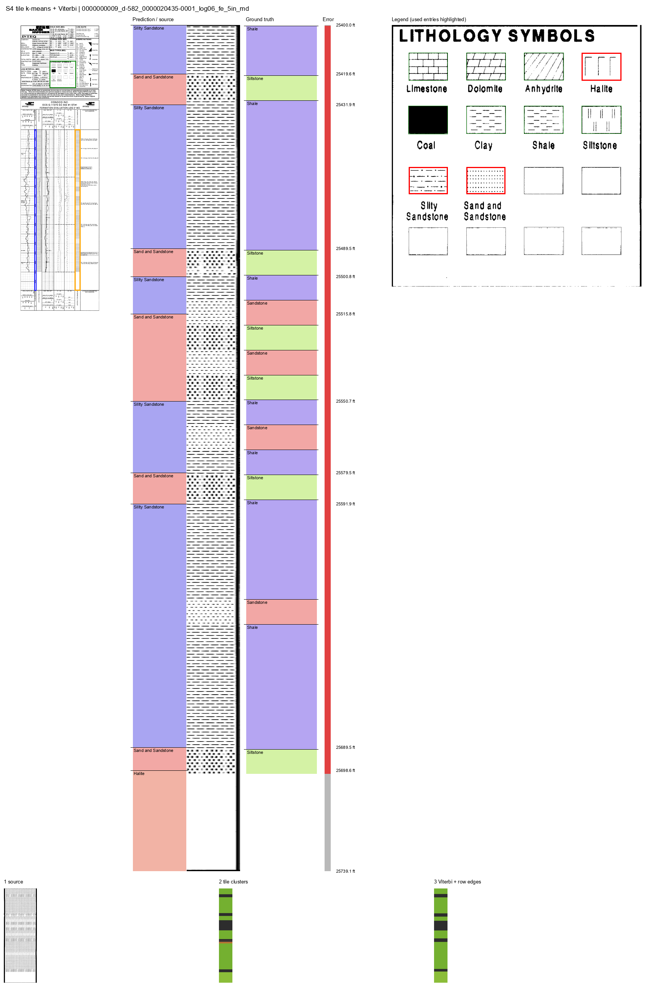

**s05_dinov2**

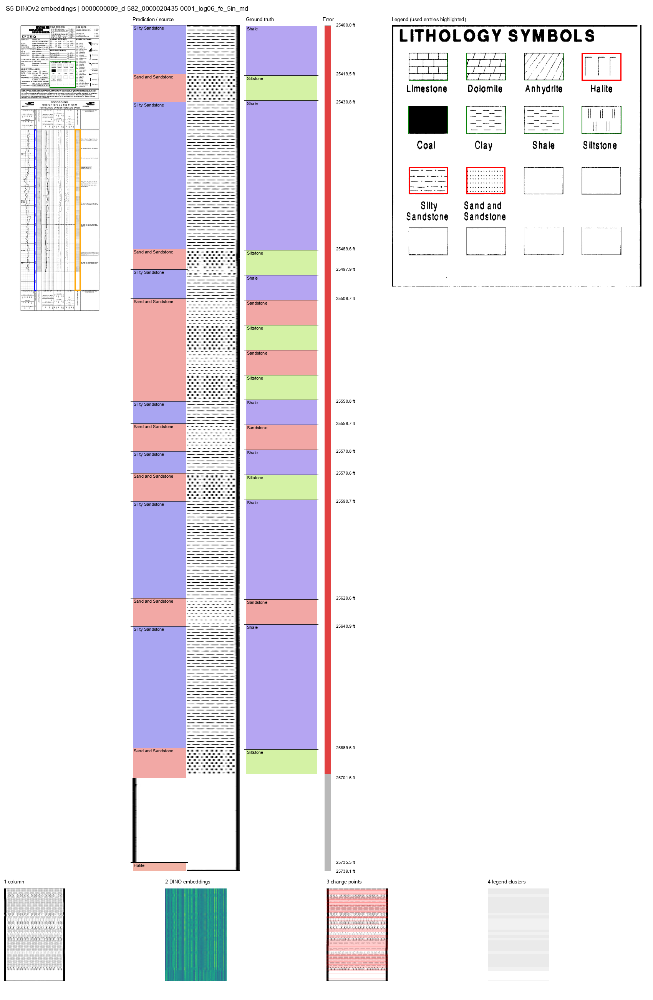

**s06_siglip**

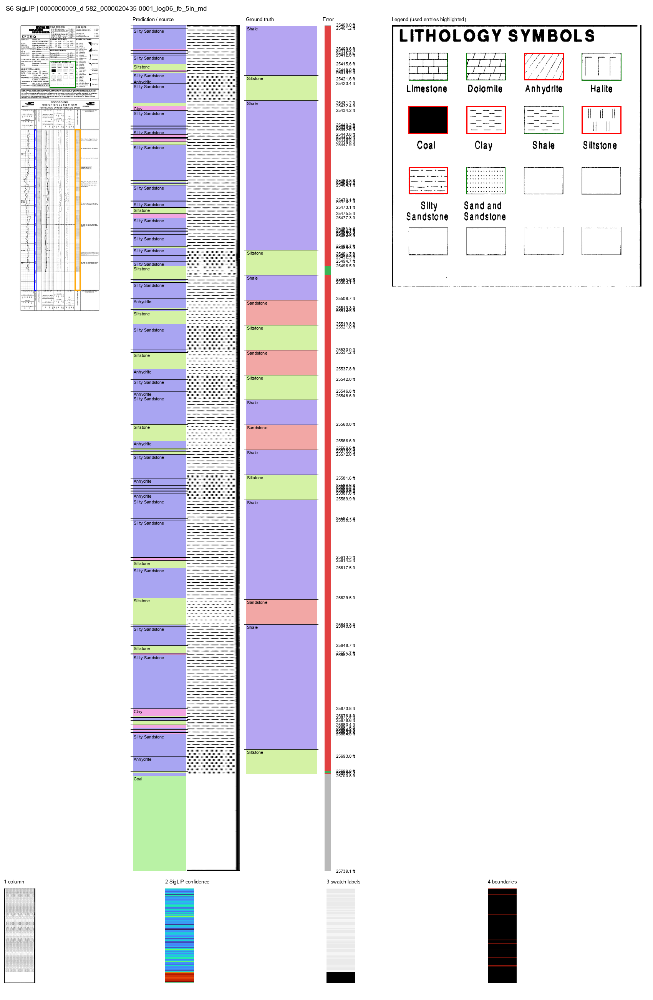

**s07_synth_cnn**

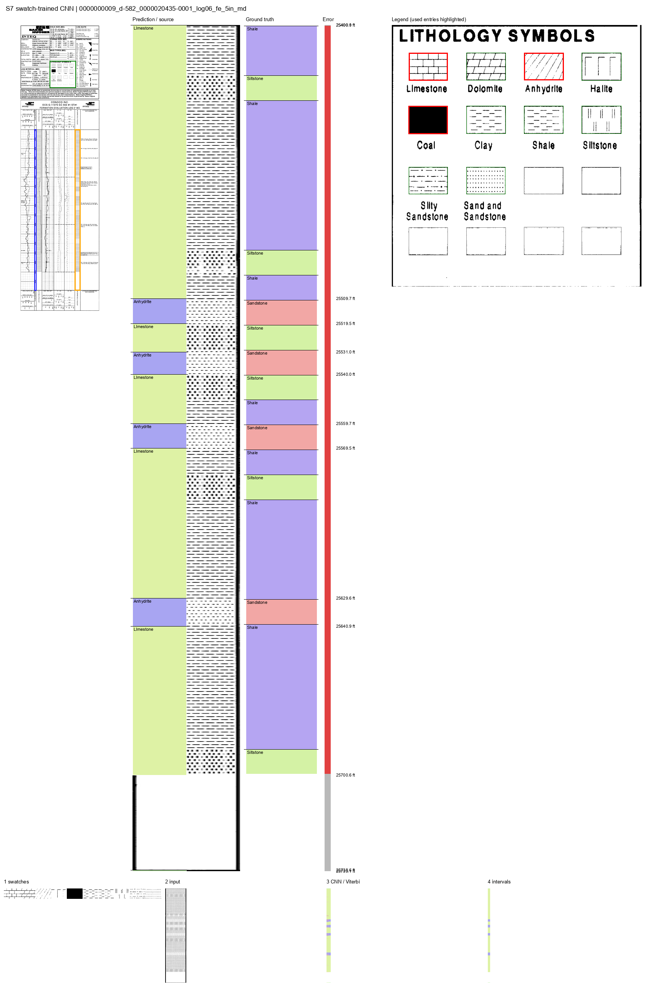

**s08_jev**

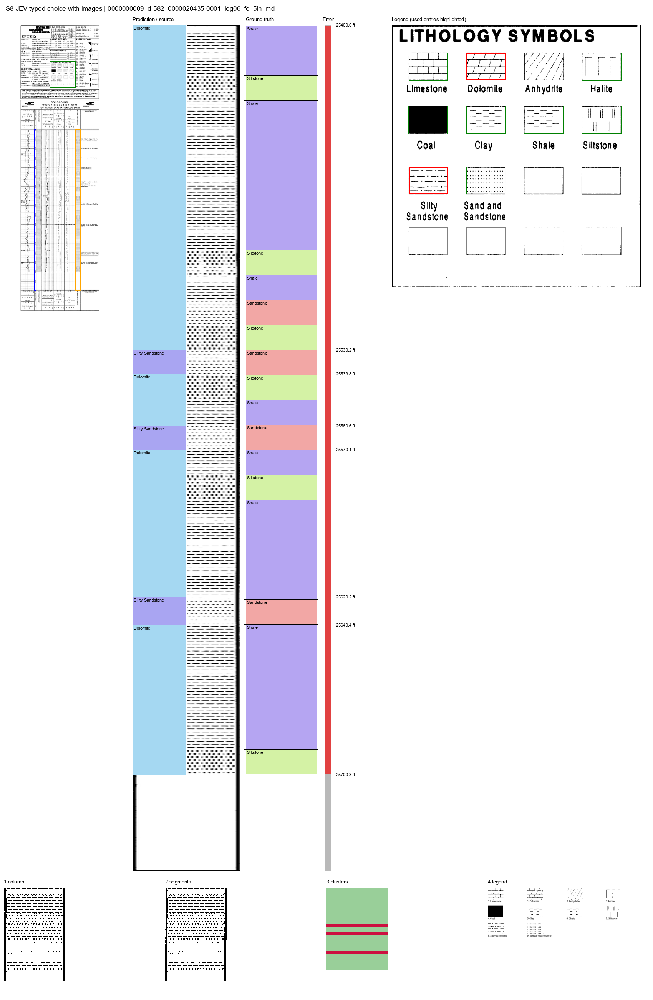

**s09_vlm_terra**

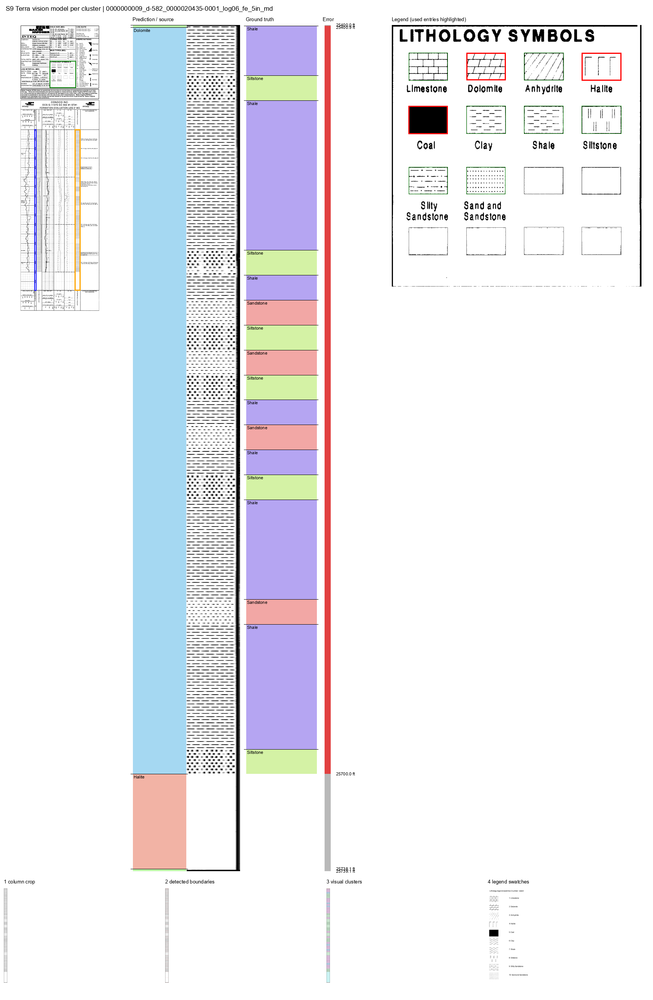

**s10_hybrid**

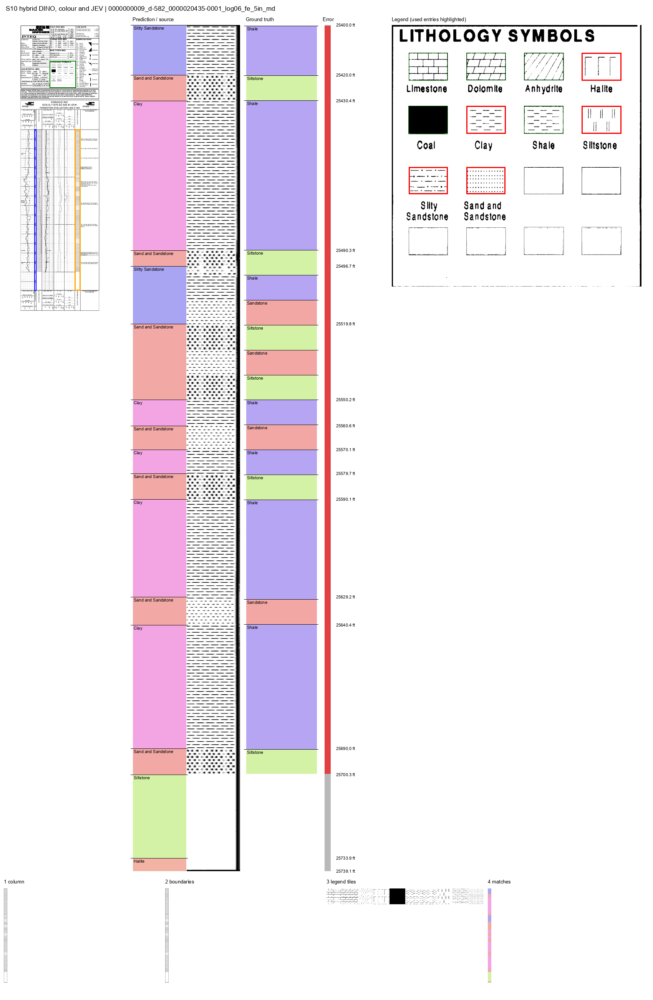

**s11_fft_legend**

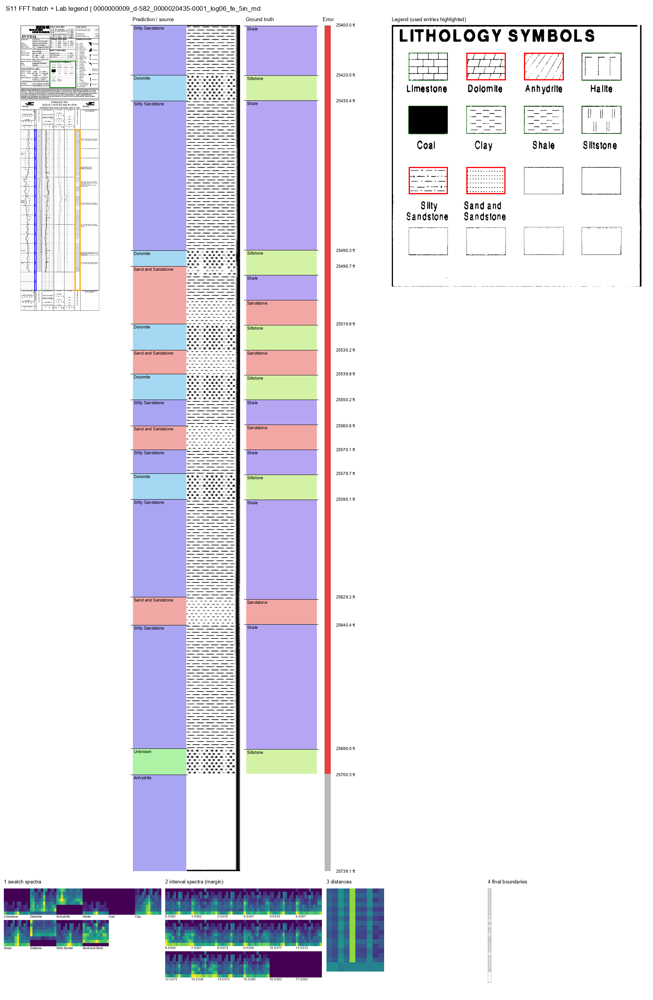

In [31]:
for p in sorted(glob.glob("bakeoff/out/s*/0000000009_d-582_0000020435-0001_log06_fe_5in_md.png")):
    display(Markdown(f"**{p.split(os.sep)[-2] if os.sep in p else p.split('/')[-2]}**"))
    display(Image(filename=p))